# 🧬 Proposed Hybrid Model: DenseNet201 + Swin-T + Cross-Attention Fusion (CAFM) + Coordinate Attention
### Skin Disease Classification (15 classes) with Edge-Enhanced Multi-Input & Full XAI

**আর্কিটেকচার সামারি (আপনার instruction অনুযায়ী ১:১ ইমপ্লিমেন্টেশন):**

| # | Component | Setting |
|---|-----------|---------|
| 1 | Input Layer | 224x224, Sobel/Laplacian edge, blend `0.7*Raw + 0.3*Edge` |
| 2 | Backbone 1 | DenseNet201 (ImageNet), feature map `7x7x1920`, প্রথম 100 layer frozen |
| 3 | Backbone 2 | Swin-T (window 7, embed dim 96), last stage `7x7x768` |
| 4 | Bridging | CAFM: 1x1 conv -> 512 ch, 8-head cross-attention, Q=DenseNet, K/V=Swin |
| 5 | Refinement | Coordinate Attention, reduction r=32, h-swish |
| 6 | Head | AdaptiveAvgPool2d -> Dropout 0.4 -> Dense 512 -> Softmax(15) |
| 7 | Training | AdamW, LR 1e-4, CosineAnnealingLR, Batch 16, Loss = `0.6*Focal + 0.4*Dice` (γ=2.0, α=0.25) |
| 8 | XAI | Grad-CAM + Grad-CAM++ (DenseNet last dense block & Swin last stage) + fused overlay + CAFM attention map |

**Training strategy:** দুই ফেজ।
Phase 1 = দুই ব্যাকবোনই frozen, শুধু CAFM + CA + head ট্রেইন (fusion module কে stabilize করার জন্য)।
Phase 2 = fine-tuning, DenseNet এর প্রথম 100 layer frozen + Swin এর প্রথম 2 stage frozen, backbone-এ discriminative LR (1e-5) আর নতুন মডিউলে 1e-4।

> নোট: dataset ও split আপনার আগের নোটবুকের মতোই (already-split train/val/test), তাই রেজাল্ট DenseNet201 (93.87%) ও Swin (96.13%) বেসলাইনের সাথে সরাসরি তুলনাযোগ্য।

In [2]:
# ============================================================
# ⚡ CELL 1 — ENVIRONMENT SETUP (Kaggle / Colab)
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import sys, subprocess

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_ensure("transformers")
_ensure("grad-cam", "pytorch_grad_cam")          # Grad-CAM / Grad-CAM++
_ensure("opencv-python-headless", "cv2")          # Sobel / Laplacian

import json, pickle, zipfile, shutil, random, time, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import cv2
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import FileLink, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import densenet201, DenseNet201_Weights

import transformers
from transformers import SwinModel

from sklearn.utils import class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve, auc, cohen_kappa_score,
                             matthews_corrcoef)
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("✅ PyTorch:", torch.__version__)
print("✅ Transformers:", transformers.__version__)
print("✅ CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("🖥️ GPU:", torch.cuda.get_device_name(0))
print("👉 Kaggle Settings > Internet = ON রাখুন (pretrained weights ডাউনলোডের জন্য)।")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.3 MB/s eta 0:00:00
✅ PyTorch: 2.10.0+cu128
✅ Transformers: 5.0.0
✅ CUDA available: True
🖥️ GPU: Tesla T4
👉 Kaggle Settings > Internet = ON রাখুন (pretrained weights ডাউনলোডের জন্য)।


In [3]:
# ============================================================
# 🔒 CELL 2 — REPRODUCIBILITY
# ============================================================
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    ws = SEED + worker_id
    np.random.seed(ws); random.seed(ws)

g = torch.Generator(); g.manual_seed(SEED)
print("✅ Seed fixed:", SEED)

# ---- Cell 2 (reproducibility) এ, manual_seed এর পরে ----
torch.use_deterministic_algorithms(True, warn_only=True)

✅ Seed fixed: 42


In [4]:
# ============================================================
# ⚙️ CELL 3 — CONFIGURATION (সব হাইপারপ্যারামিটার একজায়গায়)
# ============================================================
# ⚠️ আপনার already-split dataset path (ভেতরে train/ val/ test/ থাকবে)
DATA_PATH = "/kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2"

WORKING_DIR = "/kaggle/working/"
os.makedirs(WORKING_DIR, exist_ok=True)

MODEL_NAME = "hybrid_densenet201_swinT_cafm_ca"
SWIN_CKPT  = "microsoft/swin-tiny-patch4-window7-224"   # Swin-T: embed_dim 96, window 7x7

# ---- Input / Edge fusion ----
IMG_DIM     = 224
EDGE_MODE   = "sobel"     # "sobel" | "laplacian"
EDGE_ALPHA  = 0.7         # blended = 0.7*Raw + 0.3*Edge
USE_AUGMENT = True

# ---- Architecture ----
EMBED_DIM     = 512       # CAFM aligned channel (512 বা 1024)
NUM_HEADS     = 8         # multi-head cross attention
CA_REDUCTION  = 32        # Coordinate Attention reduction ratio r
DROPOUT       = 0.4       # 0.4 বা 0.5
HEAD_HIDDEN   = 512       # শেষ layer এর আগের dense layer

# ---- Freezing policy ----
FREEZE_CNN_FIRST_N   = 100   # DenseNet201 এর প্রথম 100 leaf layer frozen
FREEZE_SWIN_STAGES   = 2     # Swin এর প্রথম 2 stage frozen

# ---- Training ----
BATCH_SIZE   = 16          # 16 বা 32 (GPU মেমোরি অনুযায়ী)
EPOCHS_P1    = 10          # Phase 1: backbone frozen, fusion+head warm-up
EPOCHS_P2    = 25          # Phase 2: fine-tuning
LR_P1        = 1e-4
LR_HEAD_P2   = 1e-4
LR_BACKBONE  = 1e-5        # discriminative LR
WEIGHT_DECAY = 0.05        # AdamW
ETA_MIN      = 1e-6        # CosineAnnealingLR
GRAD_CLIP    = 1.0
EARLY_STOP_PATIENCE = 8
NUM_WORKERS  = 2
USE_AMP      = True

# ---- Hybrid loss ----
W_FOCAL      = 0.6
W_DICE       = 0.4
FOCAL_GAMMA  = 2.0
FOCAL_ALPHA  = 0.25
USE_CLASS_WEIGHTS = True

MODEL_DIR = os.path.join(WORKING_DIR, "models", MODEL_NAME)
os.makedirs(MODEL_DIR, exist_ok=True)
WEIGHT_PATH  = os.path.join(MODEL_DIR, f"{MODEL_NAME}_best.pt")
MISCLASS_DIR = os.path.join(WORKING_DIR, "misclassified_test")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("🖥️ Device:", device)
print(f"✅ MODEL_DIR: {MODEL_DIR}")
print(f"✅ Total epochs: {EPOCHS_P1} (phase-1) + {EPOCHS_P2} (phase-2)")

🖥️ Device: cuda
✅ MODEL_DIR: /kaggle/working/models/hybrid_densenet201_swinT_cafm_ca
✅ Total epochs: 10 (phase-1) + 25 (phase-2)


In [5]:
# ============================================================
# 📂 CELL 4 — DATASET VERIFY (কোনো নতুন split হবে না)
# ============================================================
GCS_PATH = DATA_PATH
required_splits = ["train", "val", "test"]
missing = [s for s in required_splits if not os.path.exists(os.path.join(GCS_PATH, s))]
if missing:
    raise FileNotFoundError(f"❌ পাওয়া যায়নি: {missing} — DATA_PATH ঠিক করুন।")

train_dir = os.path.join(GCS_PATH, "train")
CLASS_NAMES = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
NB_CLASSES = len(CLASS_NAMES)

for split in required_splits:
    sp = os.path.join(GCS_PATH, split)
    cds = [d for d in os.listdir(sp) if os.path.isdir(os.path.join(sp, d))]
    n = sum(len(os.listdir(os.path.join(sp, d))) for d in cds)
    print(f"  📁 {split}: {n} images, {len(cds)} classes")
    if split == "train":
        NB_TRAIN = n

print(f"\n📂 মোট ক্লাস ({NB_CLASSES}):", CLASS_NAMES)

  📁 train: 6005 images, 15 classes
  📁 val: 752 images, 15 classes
  📁 test: 750 images, 15 classes

📂 মোট ক্লাস (15): ['Acne', 'Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Fungal Infection', 'Healthy Skin', 'Nail Fungal', 'Psoriasis', 'Scabies', 'Tinea Corporis', 'Tinea Cruris', 'Tinea Faciei', 'Tinea Versicolor', 'Urticaria', 'Vitiligo']


## 🖼️ Sample Dataset Visualization

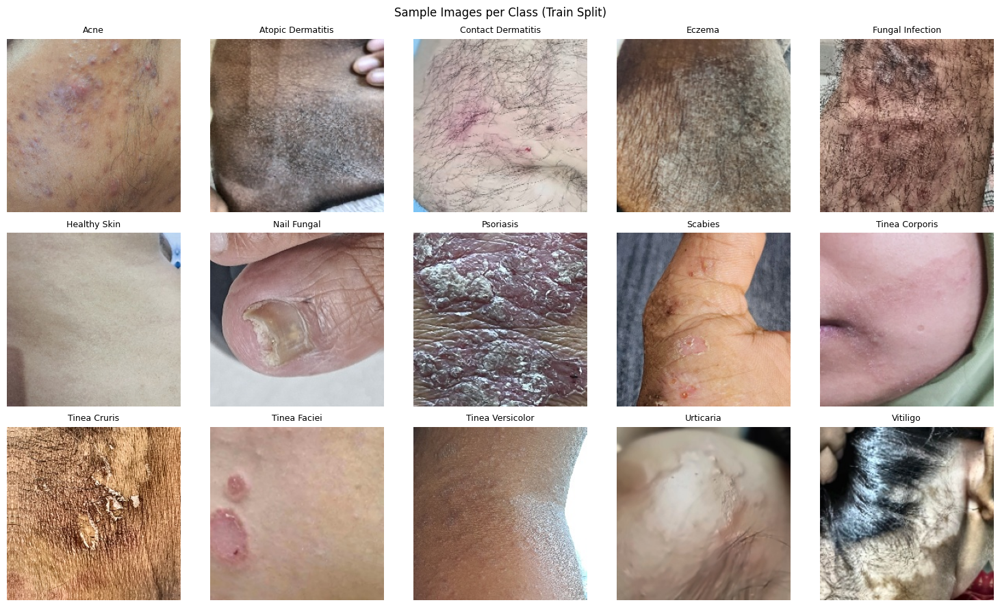

In [6]:
# ============================================================
# 🖼️ CELL 5 — প্রতি ক্লাস থেকে একটি করে sample
# ============================================================
n_show = min(NB_CLASSES, 15)
cols = 5
rows = (n_show + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = np.array(axes).reshape(-1)

for ax, cname in zip(axes, CLASS_NAMES[:n_show]):
    cdir = os.path.join(train_dir, cname)
    fname = random.choice(os.listdir(cdir))
    ax.imshow(Image.open(os.path.join(cdir, fname)).convert("RGB"))
    ax.set_title(cname, fontsize=9); ax.axis("off")
for ax in axes[n_show:]:
    ax.axis("off")

plt.suptitle("Sample Images per Class (Train Split)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "sample_dataset.png"), dpi=150)
plt.show()

## ⚡ Input Layer: Edge Enhancement Preview

Sobel/Laplacian ফিল্টার দিয়ে edge বের করে `0.7*Raw + 0.3*Edge` ব্লেন্ড করা হচ্ছে।
স্কিন লেশনের **বর্ডার/টেক্সচার** ইনফরমেশন এতে বুস্ট হয়, যেটা Tinea Versicolor আর
Atopic Dermatitis এর মতো confusing ক্লাসে সাহায্য করে। নিচের সেলটা শুধু ভিজ্যুয়াল
verification, ট্রেনিংয়ে এই কাজটা GPU-তে মডেলের ভেতরেই হয় (differentiable)।

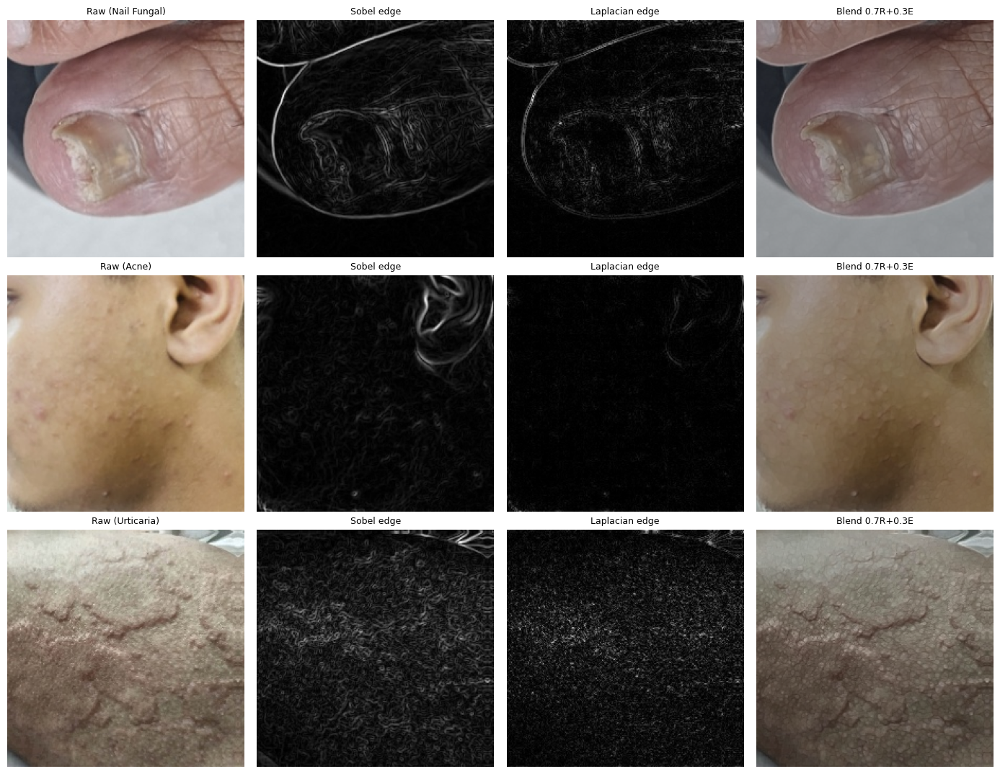

In [7]:
# ============================================================
# ⚡ CELL 6 — Edge enhancement preview (Sobel vs Laplacian vs Blend)
# ============================================================
def np_edge_preview(pil_img, mode="sobel"):
    arr = np.array(pil_img.resize((IMG_DIM, IMG_DIM)).convert("RGB")).astype(np.float32) / 255.0
    gray = cv2.cvtColor((arr * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    if mode == "sobel":
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        edge = np.sqrt(gx ** 2 + gy ** 2)
    else:
        edge = np.abs(cv2.Laplacian(gray, cv2.CV_32F, ksize=3))
    edge = edge / (edge.max() + 1e-8)
    edge3 = np.stack([edge] * 3, axis=-1)
    blend = EDGE_ALPHA * arr + (1 - EDGE_ALPHA) * edge3
    return arr, edge, np.clip(blend, 0, 1)

demo_classes = random.sample(CLASS_NAMES, min(3, NB_CLASSES))
fig, axes = plt.subplots(len(demo_classes), 4, figsize=(14, 3.6 * len(demo_classes)))
axes = np.atleast_2d(axes)
for r, cname in enumerate(demo_classes):
    cdir = os.path.join(train_dir, cname)
    img = Image.open(os.path.join(cdir, random.choice(os.listdir(cdir)))).convert("RGB")
    raw, sob, blend = np_edge_preview(img, "sobel")
    _, lap, _ = np_edge_preview(img, "laplacian")
    for c, (im, t, cmap) in enumerate([(raw, f"Raw ({cname})", None),
                                       (sob, "Sobel edge", "gray"),
                                       (lap, "Laplacian edge", "gray"),
                                       (blend, f"Blend {EDGE_ALPHA}R+{round(1-EDGE_ALPHA,1)}E", None)]):
        axes[r, c].imshow(im, cmap=cmap)
        axes[r, c].set_title(t, fontsize=9); axes[r, c].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "edge_enhancement_preview.png"), dpi=150)
plt.show()

In [8]:
# ============================================================
# 🔄 CELL 7 — DATA PIPELINE (ToTensor পর্যন্ত; normalize মডেলের ভেতরে)
# ============================================================
# ⚠️ গুরুত্বপূর্ণ ডিজাইন ডিসিশন: dataloader শুধু [0,1] টেনসর দেয়।
#    Edge-fusion + ImageNet normalization মডেলের ভেতরের প্রথম দুই মডিউলে হয়।
#    এতে (ক) GPU-তে ফাস্ট, (খ) Grad-CAM এ raw ইমেজ সরাসরি overlay করা যায়।

train_tf_list = [transforms.Resize((IMG_DIM, IMG_DIM))]
if USE_AUGMENT:
    train_tf_list += [
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    ]
train_tf_list += [transforms.ToTensor()]
train_transform = transforms.Compose(train_tf_list)
eval_transform  = transforms.Compose([transforms.Resize((IMG_DIM, IMG_DIM)), transforms.ToTensor()])

train_dataset = datasets.ImageFolder(os.path.join(GCS_PATH, "train"), transform=train_transform)
val_dataset   = datasets.ImageFolder(os.path.join(GCS_PATH, "val"),   transform=eval_transform)
test_dataset  = datasets.ImageFolder(os.path.join(GCS_PATH, "test"),  transform=eval_transform)
assert train_dataset.classes == CLASS_NAMES, "Class order mismatch!"

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          worker_init_fn=seed_worker, generator=g, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f"✅ train: {len(train_dataset)} | val: {len(val_dataset)} | test: {len(test_dataset)}")

✅ train: 6005 | val: 752 | test: 750


In [9]:
# ============================================================
# ⚖️ CELL 8 — CLASS WEIGHTS (শুধু train থেকে)
# ============================================================
y_train_list = [lbl for _, lbl in train_dataset.samples]
weights_np = class_weight.compute_class_weight(class_weight="balanced",
                                               classes=np.unique(y_train_list),
                                               y=y_train_list)
class_weights_tensor = torch.tensor(weights_np, dtype=torch.float32).to(device)
for i, c in enumerate(CLASS_NAMES):
    print(f"  {c}: {y_train_list.count(i)} images | w={weights_np[i]:.4f}")
print("✅ Class weights ready")

  Acne: 400 images | w=1.0008
  Atopic Dermatitis: 400 images | w=1.0008
  Contact Dermatitis: 400 images | w=1.0008
  Eczema: 400 images | w=1.0008
  Fungal Infection: 400 images | w=1.0008
  Healthy Skin: 400 images | w=1.0008
  Nail Fungal: 400 images | w=1.0008
  Psoriasis: 400 images | w=1.0008
  Scabies: 402 images | w=0.9959
  Tinea Corporis: 400 images | w=1.0008
  Tinea Cruris: 400 images | w=1.0008
  Tinea Faciei: 403 images | w=0.9934
  Tinea Versicolor: 400 images | w=1.0008
  Urticaria: 400 images | w=1.0008
  Vitiligo: 400 images | w=1.0008
✅ Class weights ready


# 🏗️ Proposed Architecture

```
        Input 224x224x3  (RGB, [0,1])
                 |
      [1] EdgeFusionInput  ->  0.7*Raw + 0.3*Sobel  ->  ImageNet Normalize
                 |
        +--------+--------+
        |                 |
[2] DenseNet201     [3] Swin-T (window 7, dim 96)
  7x7x1920 (local)     7x7x768 (global)
        |                 |
        |  1x1 conv -> 512 |  1x1 conv -> 512
        +--------+--------+
                 |
   [4] CAFM: 8-head Cross-Attention (Q=DenseNet, K,V=Swin) + FFN
                 |  7x7x512
   [5] Coordinate Attention (r=32, h-swish)
                 |
   [6] AdaptiveAvgPool -> Dropout 0.4 -> Dense 512 -> Softmax(15)
```

In [10]:
# ============================================================
# 🧩 CELL 9 — [1] Edge-Enhanced Multi-Input Layer
# ============================================================
class EdgeFusionInput(nn.Module):
    """Sobel/Laplacian edge বের করে raw ইমেজের সাথে ব্লেন্ড করে, তারপর ImageNet normalize.
    ফিল্টার fixed (non-learnable) kernel, তাই কোনো extra parameter লাগে না."""
    def __init__(self, mode="sobel", alpha=0.7,
                 mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)):
        super().__init__()
        self.mode, self.alpha = mode, alpha
        sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
        lap     = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
        gray_w  = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
        self.register_buffer("sobel_x", sobel_x)
        self.register_buffer("sobel_y", sobel_y)
        self.register_buffer("lap", lap)
        self.register_buffer("gray_w", gray_w)
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor(std).view(1, 3, 1, 1))

    def edge_map(self, x):
        gray = (x * self.gray_w).sum(dim=1, keepdim=True)       # B,1,H,W
        gray = F.pad(gray, (1, 1, 1, 1), mode="reflect")
        if self.mode == "sobel":
            gx = F.conv2d(gray, self.sobel_x)
            gy = F.conv2d(gray, self.sobel_y)
            e = torch.sqrt(gx ** 2 + gy ** 2 + 1e-8)
        else:
            e = torch.abs(F.conv2d(gray, self.lap))
        # per-image min-max normalize -> [0,1]
        B = e.shape[0]
        e_min = e.view(B, -1).min(dim=1)[0].view(B, 1, 1, 1)
        e_max = e.view(B, -1).max(dim=1)[0].view(B, 1, 1, 1)
        return (e - e_min) / (e_max - e_min + 1e-8)

    def forward(self, x, return_parts=False):
        e = self.edge_map(x).repeat(1, 3, 1, 1)                 # B,3,H,W
        blended = self.alpha * x + (1.0 - self.alpha) * e
        out = (blended - self.mean) / self.std
        if return_parts:
            return out, blended, e
        return out

print("✅ [1] EdgeFusionInput defined")

✅ [1] EdgeFusionInput defined


In [11]:
# ============================================================
# 🧩 CELL 10 — [2] Backbone 1: DenseNet201 (CNN / local branch)
# ============================================================
class DenseNetBranch(nn.Module):
    """Feature extraction point = global pooling এর আগের layer -> 7x7x1920"""
    def __init__(self, freeze_first_n=100, pretrained=True):
        super().__init__()
        w = DenseNet201_Weights.IMAGENET1K_V1 if pretrained else None
        self.features = densenet201(weights=w).features   # ImageNet weights
        self.out_channels = 1920
        self.freeze_first_n(freeze_first_n)

    def leaf_modules(self):
        return [m for m in self.features.modules()
                if len(list(m.children())) == 0 and len(list(m.parameters(recurse=False))) > 0]

    def freeze_first_n(self, n):
        leaves = self.leaf_modules()
        for i, m in enumerate(leaves):
            req = i >= n
            for p in m.parameters(recurse=False):
                p.requires_grad = req
        tr = sum(p.numel() for p in self.features.parameters() if p.requires_grad)
        tot = sum(p.numel() for p in self.features.parameters())
        print(f"   DenseNet201: প্রথম {n}/{len(leaves)} leaf layer frozen | trainable {tr:,}/{tot:,}")

    def freeze_all(self):
        for p in self.features.parameters():
            p.requires_grad = False

    def forward(self, x):
        return F.relu(self.features(x), inplace=False)      # B,1920,7,7

print("✅ [2] DenseNetBranch defined")

✅ [2] DenseNetBranch defined


In [12]:
# ============================================================
# 🧩 CELL 11 — [3] Backbone 2: Swin-T (Transformer / global branch)
# ============================================================
class SwinBranch(nn.Module):
    """Swin-Tiny: embed_dim 96, window 7x7, last stage output 7x7x768"""
    def __init__(self, ckpt=SWIN_CKPT, freeze_stages=2):
        super().__init__()
        self.backbone = SwinModel.from_pretrained(ckpt)
        self.out_channels = self.backbone.config.hidden_size    # 768
        cfg = self.backbone.config
        print(f"   Swin config -> embed_dim={cfg.embed_dim}, window={cfg.window_size}, "
              f"depths={cfg.depths}, heads={cfg.num_heads}, out_dim={self.out_channels}")
        self.freeze_stages(freeze_stages)

    def freeze_stages(self, n):
        for p in self.backbone.embeddings.parameters():
            p.requires_grad = (n <= 0)
        for i, layer in enumerate(self.backbone.encoder.layers):
            for p in layer.parameters():
                p.requires_grad = (i >= n)
        tr = sum(p.numel() for p in self.backbone.parameters() if p.requires_grad)
        tot = sum(p.numel() for p in self.backbone.parameters())
        print(f"   Swin-T: প্রথম {n} stage frozen | trainable {tr:,}/{tot:,}")

    def freeze_all(self):
        for p in self.backbone.parameters():
            p.requires_grad = False

    def forward(self, x):
        h = self.backbone(pixel_values=x).last_hidden_state      # B,49,768
        B, N, C = h.shape
        HW = int(math.sqrt(N))
        return h.transpose(1, 2).reshape(B, C, HW, HW)           # B,768,7,7

print("✅ [3] SwinBranch defined")

✅ [3] SwinBranch defined


In [13]:
# ============================================================
# 🧩 CELL 12 — [4] CAFM: Cross-Attention Fusion Module (মূল Novelty)
# ============================================================
class CrossAttentionFusion(nn.Module):
    """Q = DenseNet features (local context), K & V = Swin features (global context).
    ফলে মডেল লোকাল টেক্সচারের ভিত্তিতে গ্লোবাল কনটেক্সট খুঁজে নেয়."""
    def __init__(self, cnn_dim=1920, trans_dim=768, embed_dim=512, num_heads=8,
                 dropout=0.1, ffn_ratio=2):
        super().__init__()
        # Alignment: 1x1 conv দিয়ে দুই ব্রাঞ্চকেই embed_dim এ আনা
        self.cnn_proj = nn.Sequential(
            nn.Conv2d(cnn_dim, embed_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(embed_dim), nn.GELU())
        self.trans_proj = nn.Sequential(
            nn.Conv2d(trans_dim, embed_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(embed_dim), nn.GELU())

        self.pos_embed = nn.Parameter(torch.zeros(1, 49, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        self.norm_q  = nn.LayerNorm(embed_dim)
        self.norm_kv = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)

        self.norm_ffn = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * ffn_ratio), nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * ffn_ratio, embed_dim), nn.Dropout(dropout))

        # learnable residual scaling: শুরুতে fusion কে ধীরে ধীরে ঢুকতে দেয় (stable training)
        self.gamma_attn = nn.Parameter(torch.ones(1) * 0.5)
        self.gamma_glob = nn.Parameter(torch.ones(1) * 0.5)

        self.return_attn = False      # XAI এর সময় True করা হয়
        self.attn_weights = None

    def forward(self, f_cnn, f_swin):
        B, _, H, W = f_cnn.shape
        q_map = self.cnn_proj(f_cnn)                       # B,512,7,7
        kv_map = self.trans_proj(f_swin)                   # B,512,7,7

        q  = q_map.flatten(2).transpose(1, 2) + self.pos_embed     # B,49,512
        kv = kv_map.flatten(2).transpose(1, 2) + self.pos_embed    # B,49,512

        attn_out, attn_w = self.attn(self.norm_q(q), self.norm_kv(kv), self.norm_kv(kv),
                                     need_weights=self.return_attn,
                                     average_attn_weights=True)
        if self.return_attn:
            self.attn_weights = attn_w.detach()            # B,49,49

        x = q + self.gamma_attn * attn_out                 # cross-attention residual
        x = x + self.ffn(self.norm_ffn(x))                 # position-wise FFN
        x = x + self.gamma_glob * kv                       # global branch shortcut
        return x.transpose(1, 2).reshape(B, -1, H, W)      # B,512,7,7

print("✅ [4] CrossAttentionFusion (CAFM) defined")

✅ [4] CrossAttentionFusion (CAFM) defined


In [14]:
# ============================================================
# 🧩 CELL 13 — [5] Coordinate Attention (r=32, h-swish)
# ============================================================
class HSwish(nn.Module):
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0

class CoordinateAttention(nn.Module):
    """H এবং W অক্ষ আলাদাভাবে এনকোড করে, তাই spatial position ধরে রাখে,
    যেটা লেশনের border/localization বুঝতে সাহায্য করে."""
    def __init__(self, inp, reduction=32, act="hswish"):
        super().__init__()
        mip = max(8, inp // reduction)
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        self.conv1 = nn.Conv2d(inp, mip, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(mip)
        self.act = HSwish() if act == "hswish" else nn.ReLU(inplace=True)
        self.conv_h = nn.Conv2d(mip, inp, 1)
        self.conv_w = nn.Conv2d(mip, inp, 1)

    def forward(self, x):
        identity = x
        B, C, H, W = x.shape
        x_h = self.pool_h(x)                          # B,C,H,1
        x_w = self.pool_w(x).permute(0, 1, 3, 2)      # B,C,W,1
        y = torch.cat([x_h, x_w], dim=2)              # B,C,H+W,1
        y = self.act(self.bn1(self.conv1(y)))
        y_h, y_w = torch.split(y, [H, W], dim=2)
        y_w = y_w.permute(0, 1, 3, 2)
        a_h = torch.sigmoid(self.conv_h(y_h))
        a_w = torch.sigmoid(self.conv_w(y_w))
        return identity * a_h * a_w

print("✅ [5] CoordinateAttention defined")

✅ [5] CoordinateAttention defined


In [15]:
# ============================================================
# 🧩 CELL 14 — [6] পুরো Hybrid Model + Classification Head
# ============================================================
class HybridDenseSwinCAFM(nn.Module):
    def __init__(self, num_classes, edge_mode=EDGE_MODE, edge_alpha=EDGE_ALPHA,
                 embed_dim=EMBED_DIM, num_heads=NUM_HEADS, ca_reduction=CA_REDUCTION,
                 dropout=DROPOUT, head_hidden=HEAD_HIDDEN,
                 freeze_cnn_first_n=FREEZE_CNN_FIRST_N, freeze_swin_stages=FREEZE_SWIN_STAGES):
        super().__init__()
        self.edge_input = EdgeFusionInput(mode=edge_mode, alpha=edge_alpha)
        self.cnn_branch  = DenseNetBranch(freeze_first_n=freeze_cnn_first_n)
        self.swin_branch = SwinBranch(freeze_stages=freeze_swin_stages)
        self.cafm = CrossAttentionFusion(self.cnn_branch.out_channels,
                                         self.swin_branch.out_channels,
                                         embed_dim=embed_dim, num_heads=num_heads)
        self.coord_att = CoordinateAttention(embed_dim, reduction=ca_reduction)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim, head_hidden),
            nn.BatchNorm1d(head_hidden),
            HSwish(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(head_hidden, num_classes))     # logits (Softmax loss এর ভেতরে)

    def forward_features(self, x):
        x = self.edge_input(x)
        f_cnn = self.cnn_branch(x)
        f_swin = self.swin_branch(x)
        fused = self.cafm(f_cnn, f_swin)
        fused = self.coord_att(fused)
        return fused                                   # B,512,7,7

    def forward(self, x):
        return self.classifier(self.pool(self.forward_features(x)))

    def embed(self, x):
        return self.pool(self.forward_features(x)).flatten(1)   # B,512 (t-SNE এর জন্য)

    def freeze_backbones(self):
        self.cnn_branch.freeze_all(); self.swin_branch.freeze_all()

    def unfreeze_for_finetune(self, cnn_first_n=FREEZE_CNN_FIRST_N, swin_stages=FREEZE_SWIN_STAGES):
        self.cnn_branch.freeze_first_n(cnn_first_n)
        self.swin_branch.freeze_stages(swin_stages)

print("🏗️ Building hybrid model ...")
model = HybridDenseSwinCAFM(NB_CLASSES).to(device)

tot = sum(p.numel() for p in model.parameters())
print(f"\n✅ Total parameters: {tot:,}")
with torch.no_grad():
    dummy = torch.rand(2, 3, IMG_DIM, IMG_DIM, device=device)
    model.eval()
    fe = model.forward_features(dummy)
    out = model(dummy)
print(f"✅ Fused feature map: {tuple(fe.shape)}  |  Output logits: {tuple(out.shape)}")

🏗️ Building hybrid model ...
Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 198MB/s] 


   DenseNet201: প্রথম 100/401 leaf layer frozen | trainable 16,215,616/18,092,928


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/113M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Swin config -> embed_dim=96, window=7, depths=[2, 2, 6, 2], heads=[3, 6, 12, 24], out_dim=768
   Swin-T: প্রথম 2 stage frozen | trainable 26,027,064/27,519,354

✅ Total parameters: 49,416,491
✅ Fused feature map: (2, 512, 7, 7)  |  Output logits: (2, 15)


In [16]:
# ============================================================
# 📊 CELL 14b — MODEL SUMMARY (Keras-style, trainable/non-trainable)
# ============================================================
from torchinfo import summary

summary(
    model,
    input_size=(2, 3, IMG_DIM, IMG_DIM),
    col_names=["input_size", "output_size", "num_params", "trainable"],
    col_width=20,
    row_settings=["var_names"],
    depth=3,   # কত লেভেল নেস্টেড লেয়ার দেখাবে, দরকার হলে বাড়াও-কমাও
)

Layer (type (var_name))                                                               Input Shape          Output Shape         Param #              Trainable
HybridDenseSwinCAFM (HybridDenseSwinCAFM)                                             [2, 3, 224, 224]     [2, 15]              --                   Partial
├─EdgeFusionInput (edge_input)                                                        [2, 3, 224, 224]     [2, 3, 224, 224]     --                   --
├─DenseNetBranch (cnn_branch)                                                         [2, 3, 224, 224]     [2, 1920, 7, 7]      --                   Partial
│    └─Sequential (features)                                                          [2, 3, 224, 224]     [2, 1920, 7, 7]      --                   Partial
│    │    └─Conv2d (conv0)                                                            [2, 3, 224, 224]     [2, 64, 112, 112]    (9,408)              False
│    │    └─BatchNorm2d (norm0)                                

In [17]:
# ============================================================
# 📊 CELL 14c — MODULE-WISE PARAMETER BREAKDOWN
# ============================================================
import pandas as pd

def module_param_table(model):
    rows = []
    for name, module in model.named_children():
        total = sum(p.numel() for p in module.parameters())
        trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
        rows.append({
            "Module": name,
            "Total Params": total,
            "Trainable": trainable,
            "Non-trainable": total - trainable,
            "% of Total": None
        })
    df = pd.DataFrame(rows)
    grand_total = df["Total Params"].sum()
    df["% of Total"] = (df["Total Params"] / grand_total * 100).round(2)
    return df.sort_values("Total Params", ascending=False)

param_df = module_param_table(model)
print(param_df.to_string(index=False))
param_df.to_csv(os.path.join(WORKING_DIR, "module_param_breakdown.csv"), index=False)

     Module  Total Params  Trainable  Non-trainable  % of Total
swin_branch      27519354   26027064        1492290       55.69
 cnn_branch      18092928   16215616        1877312       36.61
       cafm       3507202    3507202              0        7.10
 classifier        271375     271375              0        0.55
  coord_att         25632      25632              0        0.05
 edge_input             0          0              0        0.00
       pool             0          0              0        0.00


In [18]:
# ============================================================
# ⚡ CELL 14d — FLOPs / GMACs (using thop)
# ============================================================
_ensure("thop")
from thop import profile

dummy_input = torch.rand(1, 3, IMG_DIM, IMG_DIM, device=device)
model.eval()
macs, params = profile(model, inputs=(dummy_input,), verbose=False)
print(f"GMACs (multiply-accumulate): {macs / 1e9:.2f} G")
print(f"GFLOPs (approx = 2×MACs):    {macs * 2 / 1e9:.2f} G")
print(f"Params (thop check):         {params / 1e6:.2f} M")

GMACs (multiply-accumulate): 8.87 G
GFLOPs (approx = 2×MACs):    17.75 G
Params (thop check):         48.32 M


In [19]:
# ============================================================
# 🎯 CELL 15 — [7a] Hybrid Loss = 0.6*Focal + 0.4*Dice
# ============================================================
class FocalLoss(nn.Module):
    """Multi-class focal loss. gamma=2.0 কঠিন স্যাম্পলে বেশি ওজন দেয়, alpha=0.25 scaling."""
    def __init__(self, gamma=2.0, alpha=0.25, class_weights=None, label_smoothing=0.0):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha
        self.class_weights = class_weights
        self.ls = label_smoothing

    def forward(self, logits, targets):
        logp = F.log_softmax(logits, dim=1)
        if self.ls > 0:
            n = logits.size(1)
            true_dist = torch.full_like(logp, self.ls / (n - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.ls)
            logpt = (true_dist * logp).sum(dim=1)
        else:
            logpt = logp.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = logpt.exp().clamp(min=1e-8, max=1.0)
        at = self.alpha
        if self.class_weights is not None:
            at = self.alpha * self.class_weights[targets]
        return (-at * (1 - pt) ** self.gamma * logpt).mean()

class MultiClassDiceLoss(nn.Module):
    """Soft Dice over softmax probabilities (per-class), class imbalance-এ শক্তিশালী।"""
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        onehot = F.one_hot(targets, num_classes=logits.size(1)).float()
        inter = (probs * onehot).sum(dim=0)
        card  = probs.sum(dim=0) + onehot.sum(dim=0)
        dice = (2.0 * inter + self.eps) / (card + self.eps)
        return 1.0 - dice.mean()

class HybridLoss(nn.Module):
    def __init__(self, w_focal=W_FOCAL, w_dice=W_DICE, gamma=FOCAL_GAMMA,
                 alpha=FOCAL_ALPHA, class_weights=None):
        super().__init__()
        self.focal = FocalLoss(gamma, alpha, class_weights)
        self.dice = MultiClassDiceLoss()
        self.w_f, self.w_d = w_focal, w_dice

    def forward(self, logits, targets):
        return self.w_f * self.focal(logits, targets) + self.w_d * self.dice(logits, targets)

criterion = HybridLoss(class_weights=class_weights_tensor if USE_CLASS_WEIGHTS else None)
print(f"✅ Loss = {W_FOCAL}*Focal(γ={FOCAL_GAMMA}, α={FOCAL_ALPHA}) + {W_DICE}*Dice")

✅ Loss = 0.6*Focal(γ=2.0, α=0.25) + 0.4*Dice


In [20]:
# ============================================================
# 🔁 CELL 16 — [7b] Train / Validate helper functions
# ============================================================
def make_amp():
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and torch.cuda.is_available())
        ctx = lambda: torch.amp.autocast("cuda", enabled=USE_AMP and torch.cuda.is_available())
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP and torch.cuda.is_available())
        ctx = lambda: torch.cuda.amp.autocast(enabled=USE_AMP and torch.cuda.is_available())
    return scaler, ctx

scaler, amp_ctx = make_amp()

def train_one_epoch(model, loader, optimizer, criterion, epoch_desc=""):
    model.train()
    running, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc=epoch_desc, leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with amp_ctx():
            logits = model(imgs)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
        scaler.step(optimizer); scaler.update()
        running += loss.item() * imgs.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += imgs.size(0)
        pbar.set_postfix(loss=f"{running/total:.4f}", acc=f"{correct/total:.4f}")
    return running / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, return_preds=False, return_probs=False):
    model.eval()
    running, correct, total = 0.0, 0, 0
    all_p, all_y, all_prob = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with amp_ctx():
            logits = model(imgs)
            loss = criterion(logits, labels)
        running += loss.item() * imgs.size(0)
        preds = logits.argmax(1)
        correct += (preds == labels).sum().item(); total += imgs.size(0)
        all_p.append(preds.cpu()); all_y.append(labels.cpu())
        if return_probs:
            all_prob.append(F.softmax(logits.float(), dim=1).cpu())
    y = torch.cat(all_y).numpy(); p = torch.cat(all_p).numpy()
    macro_f1 = f1_score(y, p, average="macro", zero_division=0)
    res = [running / total, correct / total, macro_f1]
    if return_preds: res += [y, p]
    if return_probs: res += [torch.cat(all_prob).numpy()]
    return tuple(res)

class EarlyStopping:
    def __init__(self, patience=8, mode="max"):
        self.patience, self.mode = patience, mode
        self.best, self.count, self.stop = None, 0, False
    def step(self, metric):
        improved = self.best is None or (metric > self.best if self.mode == "max" else metric < self.best)
        if improved:
            self.best, self.count = metric, 0
        else:
            self.count += 1
            self.stop = self.count >= self.patience
        return improved

HISTORY = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": [], "lr": []}
print("✅ Train/eval utilities ready")

✅ Train/eval utilities ready


In [21]:
# ============================================================
# 🚀 CELL 17 — PHASE 1: Backbone FROZEN, শুধু CAFM + CA + Head ট্রেইন
# ============================================================
print("=" * 60)
print("🚀 PHASE 1 — fusion + head warm-up (both backbones frozen)")
print("=" * 60)

model.freeze_backbones()
p1_params = [p for p in model.parameters() if p.requires_grad]
print(f"✅ Trainable params (phase 1): {sum(p.numel() for p in p1_params):,}")

optimizer = torch.optim.AdamW(p1_params, lr=LR_P1, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_P1, eta_min=ETA_MIN)
stopper = EarlyStopping(patience=EARLY_STOP_PATIENCE, mode="max")
best_metric = -1.0

for ep in range(1, EPOCHS_P1 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion,
                                      f"P1 Epoch {ep}/{EPOCHS_P1}")
    va_loss, va_acc, va_f1 = evaluate(model, val_loader, criterion)
    scheduler.step()
    cur_lr = optimizer.param_groups[0]["lr"]

    HISTORY["train_loss"].append(tr_loss); HISTORY["train_acc"].append(tr_acc)
    HISTORY["val_loss"].append(va_loss);   HISTORY["val_acc"].append(va_acc)
    HISTORY["val_f1"].append(va_f1);       HISTORY["lr"].append(cur_lr)

    improved = stopper.step(va_f1)
    if improved and va_f1 > best_metric:
        best_metric = va_f1
        torch.save({"model": model.state_dict(), "phase": 1, "epoch": ep, "val_f1": va_f1}, WEIGHT_PATH)
        tag = "  💾 saved"
    else:
        tag = ""
    print(f"P1 [{ep:02d}/{EPOCHS_P1}] train_loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val_loss {va_loss:.4f} acc {va_acc:.4f} F1 {va_f1:.4f} | lr {cur_lr:.2e} | "
          f"{time.time()-t0:.0f}s{tag}")
    if stopper.stop:
        print("⏹️ Early stopping (phase 1)"); break

PHASE1_EPOCHS_DONE = len(HISTORY["train_loss"])
print(f"\n✅ Phase 1 শেষ। Best val macro-F1: {best_metric:.4f}")

🚀 PHASE 1 — fusion + head warm-up (both backbones frozen)
✅ Trainable params (phase 1): 3,804,209


P1 Epoch 1/10:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:897.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


P1 [01/10] train_loss 0.3747 acc 0.7287 | val_loss 0.4423 acc 0.7753 F1 0.7812 | lr 9.76e-05 | 66s  💾 saved


P1 Epoch 2/10:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (21 outputs left out)

P1 [09/10] train_loss 0.1421 acc 0.9900 | val_loss 0.3953 acc 0.8976 F1 0.8992 | lr 3.42e-06 | 51s


P1 Epoch 10/10:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


P1 [10/10] train_loss 0.1429 acc 0.9873 | val_loss 0.3908 acc 0.9122 F1 0.9135 | lr 1.00e-06 | 51s

✅ Phase 1 শেষ। Best val macro-F1: 0.9285


In [22]:
# ============================================================
# 🔧 CELL 18 — PHASE 2: FINE-TUNING (discriminative LR)
# ============================================================
print("=" * 60)
print("🔧 PHASE 2 — fine-tuning: DenseNet প্রথম 100 layer + Swin প্রথম 2 stage frozen")
print("=" * 60)

# Phase 1 এর সেরা ওয়েট থেকে শুরু
ckpt = torch.load(WEIGHT_PATH, map_location=device)
model.load_state_dict(ckpt["model"])
print(f"✅ Phase-1 best (epoch {ckpt['epoch']}, F1 {ckpt['val_f1']:.4f}) লোড হলো")

model.unfreeze_for_finetune(FREEZE_CNN_FIRST_N, FREEZE_SWIN_STAGES)

backbone_params, new_params = [], []
for n, p in model.named_parameters():
    if not p.requires_grad:
        continue
    (backbone_params if (n.startswith("cnn_branch") or n.startswith("swin_branch")) else new_params).append(p)

print(f"✅ Backbone trainable: {sum(p.numel() for p in backbone_params):,} (lr {LR_BACKBONE})")
print(f"✅ New modules trainable: {sum(p.numel() for p in new_params):,} (lr {LR_HEAD_P2})")

optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": LR_BACKBONE},
     {"params": new_params, "lr": LR_HEAD_P2}],
    weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_P2, eta_min=ETA_MIN)
stopper = EarlyStopping(patience=EARLY_STOP_PATIENCE, mode="max")

for ep in range(1, EPOCHS_P2 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion,
                                      f"P2 Epoch {ep}/{EPOCHS_P2}")
    va_loss, va_acc, va_f1 = evaluate(model, val_loader, criterion)
    scheduler.step()
    cur_lr = optimizer.param_groups[-1]["lr"]

    HISTORY["train_loss"].append(tr_loss); HISTORY["train_acc"].append(tr_acc)
    HISTORY["val_loss"].append(va_loss);   HISTORY["val_acc"].append(va_acc)
    HISTORY["val_f1"].append(va_f1);       HISTORY["lr"].append(cur_lr)

    improved = stopper.step(va_f1)
    if improved and va_f1 > best_metric:
        best_metric = va_f1
        torch.save({"model": model.state_dict(), "phase": 2, "epoch": ep, "val_f1": va_f1}, WEIGHT_PATH)
        tag = "  💾 saved"
    else:
        tag = ""
    print(f"P2 [{ep:02d}/{EPOCHS_P2}] train_loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val_loss {va_loss:.4f} acc {va_acc:.4f} F1 {va_f1:.4f} | lr {cur_lr:.2e} | "
          f"{time.time()-t0:.0f}s{tag}")
    if stopper.stop:
        print("⏹️ Early stopping (phase 2)"); break

with open(os.path.join(MODEL_DIR, "history.json"), "w") as f:
    json.dump(HISTORY, f, indent=2)
print(f"\n✅ Training complete. Best val macro-F1: {best_metric:.4f}")

🔧 PHASE 2 — fine-tuning: DenseNet প্রথম 100 layer + Swin প্রথম 2 stage frozen
✅ Phase-1 best (epoch 4, F1 0.9285) লোড হলো
   DenseNet201: প্রথম 100/401 leaf layer frozen | trainable 16,215,616/18,092,928
   Swin-T: প্রথম 2 stage frozen | trainable 26,025,528/27,519,354
✅ Backbone trainable: 42,241,144 (lr 1e-05)
✅ New modules trainable: 3,804,209 (lr 0.0001)


P2 Epoch 1/25:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


P2 [01/25] train_loss 0.1518 acc 0.9737 | val_loss 0.3870 acc 0.9388 F1 0.9385 | lr 9.96e-05 | 98s  💾 saved


P2 Epoch 2/25:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (63 outputs left out)

P2 [23/25] train_loss 0.0102 acc 0.9982 | val_loss 0.0375 acc 0.9947 F1 0.9947 | lr 2.56e-06 | 97s


P2 Epoch 24/25:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


P2 [24/25] train_loss 0.0108 acc 0.9982 | val_loss 0.0337 acc 0.9934 F1 0.9933 | lr 1.39e-06 | 96s
⏹️ Early stopping (phase 2)

✅ Training complete. Best val macro-F1: 0.9960


## 📈 Training Curves (honest plot, কোনো crop/scale trick ছাড়া)

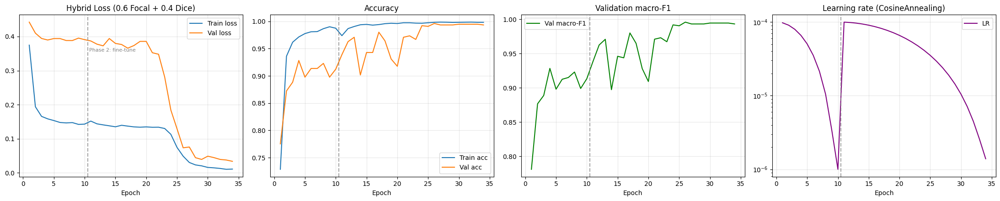

In [23]:
# ============================================================
# 📈 CELL 19 — Loss / Accuracy / F1 / LR curves
# ============================================================
ep_axis = np.arange(1, len(HISTORY["train_loss"]) + 1)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

axes[0].plot(ep_axis, HISTORY["train_loss"], label="Train loss")
axes[0].plot(ep_axis, HISTORY["val_loss"], label="Val loss")
axes[0].set_title("Hybrid Loss (0.6 Focal + 0.4 Dice)")

axes[1].plot(ep_axis, HISTORY["train_acc"], label="Train acc")
axes[1].plot(ep_axis, HISTORY["val_acc"], label="Val acc")
axes[1].set_title("Accuracy")

axes[2].plot(ep_axis, HISTORY["val_f1"], color="green", label="Val macro-F1")
axes[2].set_title("Validation macro-F1")

axes[3].plot(ep_axis, HISTORY["lr"], color="purple", label="LR")
axes[3].set_yscale("log"); axes[3].set_title("Learning rate (CosineAnnealing)")

for ax in axes:
    ax.axvline(PHASE1_EPOCHS_DONE + 0.5, color="gray", ls="--", alpha=0.7)
    ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
axes[0].text(PHASE1_EPOCHS_DONE + 0.7, max(HISTORY["train_loss"]) * 0.95,
             "Phase 2: fine-tune", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, f"{MODEL_NAME}_metrics.png"), dpi=150)
plt.show()

In [24]:
import os
import matplotlib.pyplot as plt
import numpy as np

ep_axis = np.arange(1, len(HISTORY["train_loss"]) + 1)

plt.style.use("default")

SAVE_DIR = MODEL_DIR

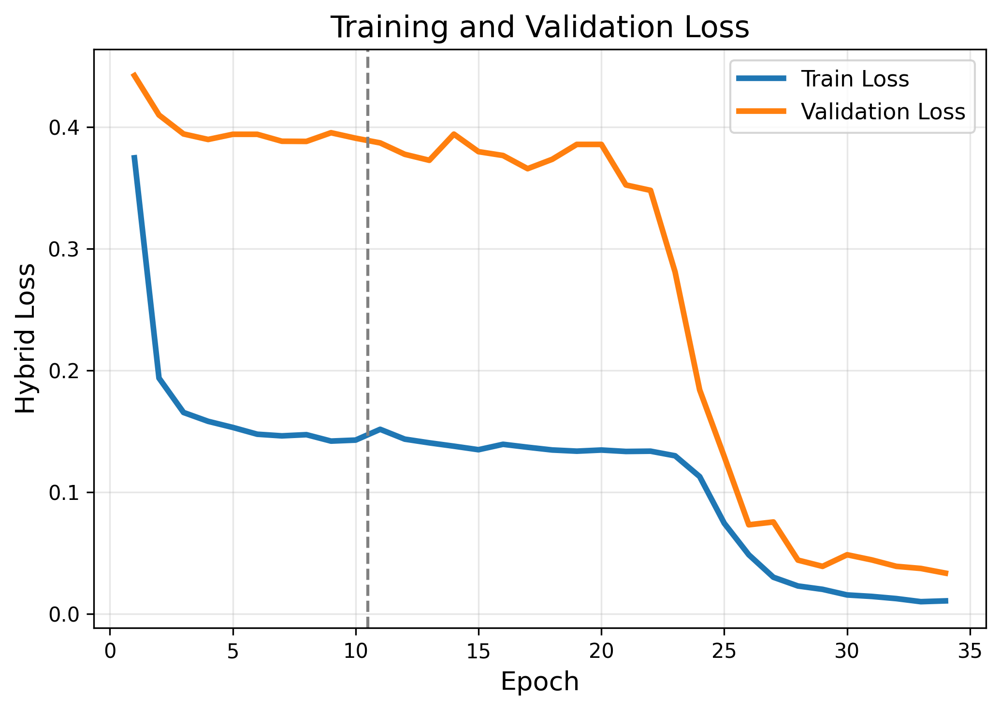

In [25]:
plt.figure(figsize=(7,5), dpi=300)

plt.plot(ep_axis, HISTORY["train_loss"],
         linewidth=2.8,
         label="Train Loss")

plt.plot(ep_axis, HISTORY["val_loss"],
         linewidth=2.8,
         label="Validation Loss")

plt.axvline(PHASE1_EPOCHS_DONE + 0.5,
            color="gray",
            linestyle="--",
            linewidth=1.5)

plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Hybrid Loss", fontsize=13)
plt.title("Training and Validation Loss", fontsize=15)

plt.grid(alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()

plt.savefig(os.path.join(SAVE_DIR,"loss_curve.png"),
            dpi=300,
            bbox_inches="tight")

plt.show()

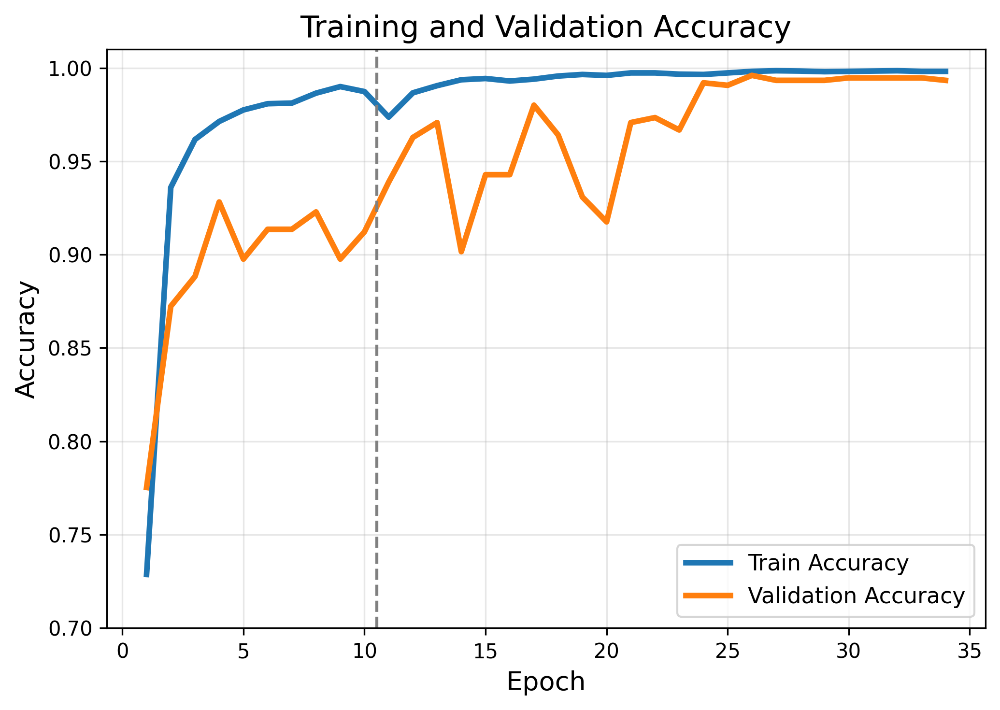

In [26]:
plt.figure(figsize=(7,5), dpi=300)

plt.plot(ep_axis, HISTORY["train_acc"],
         linewidth=2.8,
         label="Train Accuracy")

plt.plot(ep_axis, HISTORY["val_acc"],
         linewidth=2.8,
         label="Validation Accuracy")

plt.axvline(PHASE1_EPOCHS_DONE + 0.5,
            color="gray",
            linestyle="--",
            linewidth=1.5)

plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Accuracy", fontsize=13)
plt.title("Training and Validation Accuracy", fontsize=15)

plt.ylim(0.70,1.01)

plt.grid(alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()

plt.savefig(os.path.join(SAVE_DIR,"accuracy_curve.png"),
            dpi=300,
            bbox_inches="tight")

plt.show()

## 🎯 Final Evaluation — TEST SET only

In [27]:
# ============================================================
# 🎯 CELL 20 — Best checkpoint লোড করে TEST evaluation
# ============================================================
ckpt = torch.load(WEIGHT_PATH, map_location=device)
model.load_state_dict(ckpt["model"])
model.to(device).eval()
print(f"✅ Best checkpoint (phase {ckpt['phase']}, epoch {ckpt['epoch']}, val F1 {ckpt['val_f1']:.4f})")

te_loss, te_acc, te_f1, test_gts, test_preds, test_probs = evaluate(
    model, test_loader, criterion, return_preds=True, return_probs=True)

kappa = cohen_kappa_score(test_gts, test_preds)
mcc = matthews_corrcoef(test_gts, test_preds)

print("\n" + "=" * 60)
print(f"📋 FINAL TEST RESULTS (n={len(test_gts)})")
print("=" * 60)
print(f"✅ Test Accuracy : {te_acc*100:.2f}%")
print(f"✅ Macro F1      : {te_f1*100:.2f}%")
print(f"✅ Cohen's Kappa : {kappa:.4f}")
print(f"✅ MCC           : {mcc:.4f}")
print(f"✅ Test Loss     : {te_loss:.4f}\n")

report = classification_report(test_gts, test_preds, target_names=CLASS_NAMES,
                               digits=4, zero_division=0)
print(report)
with open(os.path.join(MODEL_DIR, "final_test_classification_report.txt"), "w") as f:
    f.write(f"Accuracy: {te_acc:.4f}\nMacroF1: {te_f1:.4f}\nKappa: {kappa:.4f}\nMCC: {mcc:.4f}\n\n")
    f.write(report)

# Baseline comparison table (আপনার আগের দুই নোটবুকের রেজাল্ট)
comp = pd.DataFrame({
    "Model": ["DenseNet201 (baseline)", "Swin (baseline)", "Proposed Hybrid (CAFM+CA)"],
    "Test Accuracy (%)": [93.87, 96.13, round(te_acc * 100, 2)],
    "Macro F1 (%)": [94.00, 96.00, round(te_f1 * 100, 2)],
})
comp.to_csv(os.path.join(MODEL_DIR, "comparison_with_baselines.csv"), index=False)
display(comp)

✅ Best checkpoint (phase 2, epoch 16, val F1 0.9960)

📋 FINAL TEST RESULTS (n=750)
✅ Test Accuracy : 97.87%
✅ Macro F1      : 97.86%
✅ Cohen's Kappa : 0.9771
✅ MCC           : 0.9772
✅ Test Loss     : 0.1632

                    precision    recall  f1-score   support

              Acne     0.9434    1.0000    0.9709        50
 Atopic Dermatitis     1.0000    1.0000    1.0000        50
Contact Dermatitis     1.0000    1.0000    1.0000        50
            Eczema     1.0000    0.9600    0.9796        50
  Fungal Infection     1.0000    0.8800    0.9362        50
      Healthy Skin     0.9259    1.0000    0.9615        50
       Nail Fungal     1.0000    1.0000    1.0000        50
         Psoriasis     1.0000    1.0000    1.0000        50
           Scabies     0.9615    1.0000    0.9804        50
    Tinea Corporis     0.8868    0.9400    0.9126        50
      Tinea Cruris     1.0000    1.0000    1.0000        50
      Tinea Faciei     1.0000    1.0000    1.0000        50
  Tinea Ve

,Model,Test Accuracy (%),Macro F1 (%)
0,DenseNet201 (baseline),93.87,94.00
1,Swin (baseline),96.13,96.00
2,Proposed Hybrid (CAFM+CA),97.87,97.86


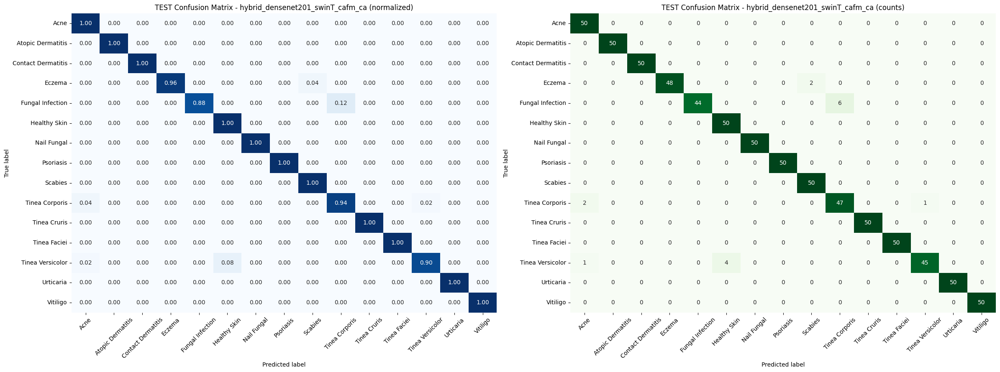

In [28]:
# ============================================================
# 🔢 CELL 21 — Confusion Matrix (normalized + raw count)
# ============================================================
def plot_confusion(gts, preds, class_names, title, save_path=None):
    cm = confusion_matrix(gts, preds)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(24, 9))
    sn.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[0],
               xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[0].set_title(title + " (normalized)")
    sn.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
               xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[1].set_title(title + " (counts)")
    for ax in axes:
        ax.set_ylabel("True label"); ax.set_xlabel("Predicted label")
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(MODEL_DIR, save_path), dpi=150)
    plt.show()
    return cm

con_mat = plot_confusion(test_gts, test_preds, CLASS_NAMES,
                         f"TEST Confusion Matrix - {MODEL_NAME}", "confusion_matrix.png")

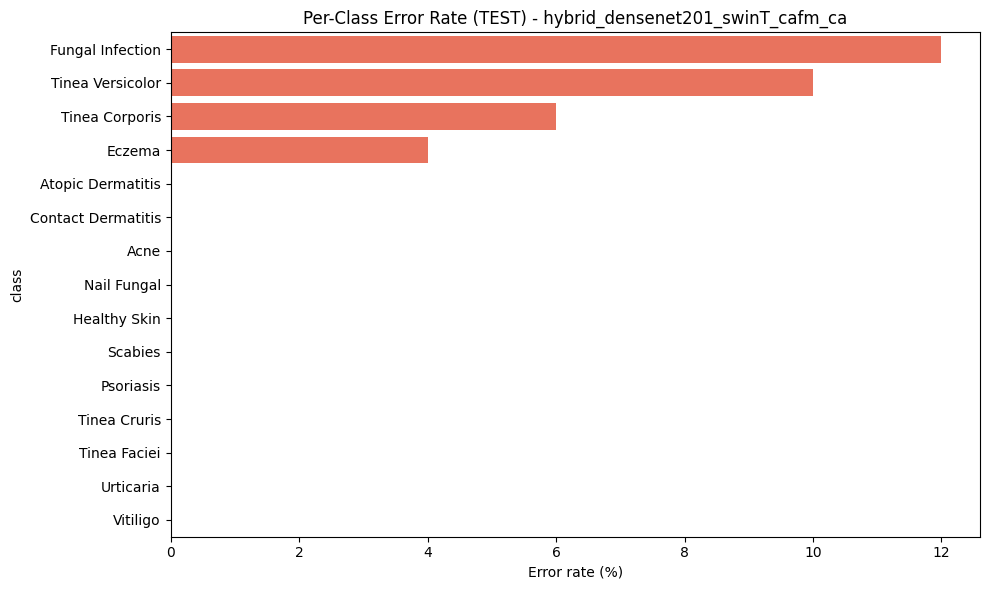

,class,wrong,total,error_rate_%
4,Fungal Infection,6,50,12.0
12,Tinea Versicolor,5,50,10.0
9,Tinea Corporis,3,50,6.0
3,Eczema,2,50,4.0
1,Atopic Dermatitis,0,50,0.0
2,Contact Dermatitis,0,50,0.0
0,Acne,0,50,0.0
6,Nail Fungal,0,50,0.0
5,Healthy Skin,0,50,0.0
8,Scabies,0,50,0.0


✅ 16টা misclassified ছবি সেভ হয়েছে: /kaggle/working/misclassified_test


In [29]:
# ============================================================
# ❌ CELL 22 — Per-class error analysis + misclassified images সেভ
# ============================================================
os.makedirs(MISCLASS_DIR, exist_ok=True)

per_total = {c: 0 for c in CLASS_NAMES}
per_wrong = {c: 0 for c in CLASS_NAMES}
for gt, pr in zip(test_gts, test_preds):
    per_total[CLASS_NAMES[gt]] += 1
    if gt != pr:
        per_wrong[CLASS_NAMES[gt]] += 1

err_df = pd.DataFrame({"class": CLASS_NAMES,
                       "wrong": [per_wrong[c] for c in CLASS_NAMES],
                       "total": [per_total[c] for c in CLASS_NAMES]})
err_df["error_rate_%"] = (err_df["wrong"] / err_df["total"] * 100).round(2)
err_df = err_df.sort_values("error_rate_%", ascending=False)
err_df.to_csv(os.path.join(MODEL_DIR, "per_class_error_summary.csv"), index=False)

plt.figure(figsize=(10, 6))
sn.barplot(data=err_df, y="class", x="error_rate_%", color="tomato")
plt.title(f"Per-Class Error Rate (TEST) - {MODEL_NAME}")
plt.xlabel("Error rate (%)"); plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "per_class_error_analysis.png"), dpi=150)
plt.show()
display(err_df)

# test_loader shuffle=False, তাই ImageFolder এর sample order-ই prediction order
test_filepaths = [p for p, _ in test_dataset.samples]
n_saved = 0
for fp, gt, pr in zip(test_filepaths, test_gts, test_preds):
    if gt != pr:
        out_dir = os.path.join(MISCLASS_DIR, f"true_{CLASS_NAMES[gt]}_pred_{CLASS_NAMES[pr]}")
        os.makedirs(out_dir, exist_ok=True)
        shutil.copy(fp, os.path.join(out_dir, os.path.basename(fp)))
        n_saved += 1
print(f"✅ {n_saved}টা misclassified ছবি সেভ হয়েছে: {MISCLASS_DIR}")

In [31]:
# ============================================================
# 🔁 5-Fold Stratified Cross-Validation
# ============================================================
# ⚠️ চালানোর আগে নিশ্চিত করুন Cell 1–22 (setup, model classes, loss, train/eval ফাংশন,
#    EarlyStopping) আগে রান করা আছে — এই cell সেগুলোর উপর নির্ভর করে।

from sklearn.model_selection import StratifiedKFold, train_test_split
from scipy import stats as sstats

K_FOLDS = 5
KFOLD_EPOCHS_P1 = 6        # সময় বাঁচাতে কমানো — চাইলে EPOCHS_P1 বসান
KFOLD_EPOCHS_P2 = 15       # সময় বাঁচাতে কমানো — চাইলে EPOCHS_P2 বসান
KFOLD_SEED = 42

class PathListDataset(torch.utils.data.Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])

# ---- সব split মিলিয়ে (path, label) pool বানানো ----
all_samples = train_dataset.samples + val_dataset.samples + test_dataset.samples
all_paths  = np.array([p for p, _ in all_samples])
all_labels = np.array([l for _, l in all_samples])
print(f"✅ Total pooled samples for {K_FOLDS}-Fold CV: {len(all_paths)}")

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=KFOLD_SEED)
fold_results = []

for fold, (trainval_idx, test_idx) in enumerate(skf.split(all_paths, all_labels), start=1):
    print("\n" + "=" * 70)
    print(f"🔁 FOLD {fold}/{K_FOLDS}")
    print("=" * 70)

    tr_idx, va_idx = train_test_split(
        trainval_idx, test_size=0.1, stratify=all_labels[trainval_idx], random_state=KFOLD_SEED)

    fold_train_ds = PathListDataset(all_paths[tr_idx], all_labels[tr_idx], train_transform)
    fold_val_ds   = PathListDataset(all_paths[va_idx], all_labels[va_idx], eval_transform)
    fold_test_ds  = PathListDataset(all_paths[test_idx], all_labels[test_idx], eval_transform)

    fold_train_loader = DataLoader(fold_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    fold_val_loader   = DataLoader(fold_val_ds, batch_size=BATCH_SIZE, shuffle=False,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_test_loader  = DataLoader(fold_test_ds, batch_size=BATCH_SIZE, shuffle=False,
                                    num_workers=NUM_WORKERS, pin_memory=True)

    y_fold_train = all_labels[tr_idx]
    w_np = class_weight.compute_class_weight(class_weight="balanced",
                                              classes=np.unique(y_fold_train), y=y_fold_train)
    w_tensor = torch.tensor(w_np, dtype=torch.float32).to(device)
    fold_criterion = HybridLoss(class_weights=w_tensor if USE_CLASS_WEIGHTS else None)

    torch.manual_seed(KFOLD_SEED + fold)
    fold_model = HybridDenseSwinCAFM(NB_CLASSES).to(device)
    fold_ckpt_path = os.path.join(MODEL_DIR, f"kfold{fold}_best.pt")

    # ---- Phase 1: backbones frozen ----
    fold_model.freeze_backbones()
    p1_params = [p for p in fold_model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(p1_params, lr=LR_P1, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=KFOLD_EPOCHS_P1, eta_min=ETA_MIN)
    stopper = EarlyStopping(patience=5, mode="max")
    best_f1 = -1.0
    for ep in range(1, KFOLD_EPOCHS_P1 + 1):
        train_one_epoch(fold_model, fold_train_loader, opt, fold_criterion, f"Fold{fold} P1 {ep}/{KFOLD_EPOCHS_P1}")
        _, va_acc, va_f1 = evaluate(fold_model, fold_val_loader, fold_criterion)
        sch.step()
        improved = stopper.step(va_f1)
        if improved and va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": fold_model.state_dict()}, fold_ckpt_path)
        print(f"  P1[{ep:02d}] val_acc {va_acc:.4f} val_f1 {va_f1:.4f}")
        if stopper.stop:
            print("  ⏹️ early stop (phase 1)"); break

    ckpt = torch.load(fold_ckpt_path, map_location=device)
    fold_model.load_state_dict(ckpt["model"])

    # ---- Phase 2: fine-tuning ----
    fold_model.unfreeze_for_finetune(FREEZE_CNN_FIRST_N, FREEZE_SWIN_STAGES)
    backbone_p, new_p = [], []
    for n_, p in fold_model.named_parameters():
        if not p.requires_grad:
            continue
        (backbone_p if (n_.startswith("cnn_branch") or n_.startswith("swin_branch")) else new_p).append(p)
    opt = torch.optim.AdamW(
        [{"params": backbone_p, "lr": LR_BACKBONE}, {"params": new_p, "lr": LR_HEAD_P2}],
        weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=KFOLD_EPOCHS_P2, eta_min=ETA_MIN)
    stopper = EarlyStopping(patience=8, mode="max")
    for ep in range(1, KFOLD_EPOCHS_P2 + 1):
        train_one_epoch(fold_model, fold_train_loader, opt, fold_criterion, f"Fold{fold} P2 {ep}/{KFOLD_EPOCHS_P2}")
        _, va_acc, va_f1 = evaluate(fold_model, fold_val_loader, fold_criterion)
        sch.step()
        improved = stopper.step(va_f1)
        if improved and va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": fold_model.state_dict()}, fold_ckpt_path)
        print(f"  P2[{ep:02d}] val_acc {va_acc:.4f} val_f1 {va_f1:.4f}")
        if stopper.stop:
            print("  ⏹️ early stop (phase 2)"); break

    ckpt = torch.load(fold_ckpt_path, map_location=device)
    fold_model.load_state_dict(ckpt["model"])

    # ---- held-out fold test performance ----
    te_loss, te_acc, te_f1, te_gts, te_preds, te_probs = evaluate(
        fold_model, fold_test_loader, fold_criterion, return_preds=True, return_probs=True)
    y_bin_f = label_binarize(te_gts, classes=list(range(NB_CLASSES)))
    fold_auc = roc_auc_score(y_bin_f, te_probs, average="macro", multi_class="ovr")
    fold_kappa = cohen_kappa_score(te_gts, te_preds)

    fold_results.append({"fold": fold, "accuracy": te_acc, "macro_f1": te_f1,
                          "macro_auc": fold_auc, "kappa": fold_kappa, "n_test": len(te_gts)})
    print(f"✅ Fold {fold} TEST: Acc={te_acc*100:.2f}%  F1={te_f1*100:.2f}%  AUC={fold_auc:.4f}  Kappa={fold_kappa:.4f}")

    del fold_model
    torch.cuda.empty_cache()

# ---- Summary: mean ± std + 95% CI (t-distribution) ----
kfold_df = pd.DataFrame(fold_results)
kfold_df.to_csv(os.path.join(MODEL_DIR, "kfold_results.csv"), index=False)

def mean_ci(x, conf=0.95):
    x = np.array(x, dtype=float)
    m, s, n_ = x.mean(), x.std(ddof=1), len(x)
    se = s / np.sqrt(n_)
    h = se * sstats.t.ppf((1 + conf) / 2, n_ - 1)
    return m, s, m - h, m + h

print("\n" + "=" * 70)
print(f"📊 {K_FOLDS}-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 70)
for metric in ["accuracy", "macro_f1", "macro_auc", "kappa"]:
    m, s, lo, hi = mean_ci(kfold_df[metric])
    if metric == "kappa":
        print(f"{metric:>10}: {m:.4f} ± {s:.4f}  (95% CI: [{lo:.4f}, {hi:.4f}])")
    else:
        print(f"{metric:>10}: {m*100:.2f}% ± {s*100:.2f}%  (95% CI: [{lo*100:.2f}%, {hi*100:.2f}%])")
display(kfold_df)

✅ Total pooled samples for 5-Fold CV: 7507

🔁 FOLD 1/5
   DenseNet201: প্রথম 100/401 leaf layer frozen | trainable 16,215,616/18,092,928


Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Swin config -> embed_dim=96, window=7, depths=[2, 2, 6, 2], heads=[3, 6, 12, 24], out_dim=768
   Swin-T: প্রথম 2 stage frozen | trainable 26,027,064/27,519,354


Fold1 P1 1/6:   0%|          | 0/337 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (322 outputs left out)

Fold5 P2 15/15:   0%|          | 0/337 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  P2[15] val_acc 0.9967 val_f1 0.9967
✅ Fold 5 TEST: Acc=99.07%  F1=99.07%  AUC=0.9999  Kappa=0.9900

📊 5-FOLD CROSS-VALIDATION SUMMARY
  accuracy: 99.04% ± 0.39%  (95% CI: [98.56%, 99.52%])
  macro_f1: 99.04% ± 0.39%  (95% CI: [98.56%, 99.52%])
 macro_auc: 99.98% ± 0.01%  (95% CI: [99.97%, 99.99%])
     kappa: 0.9897 ± 0.0042  (95% CI: [0.9845, 0.9949])


,fold,accuracy,macro_f1,macro_auc,kappa,n_test
0,1,0.985353,0.985395,0.999707,0.984307,1502
1,2,0.988682,0.988673,0.999687,0.987873,1502
2,3,0.991339,0.991331,0.999871,0.990720,1501
3,4,0.996003,0.996006,0.999842,0.995717,1501
4,5,0.990673,0.990671,0.999859,0.990007,1501


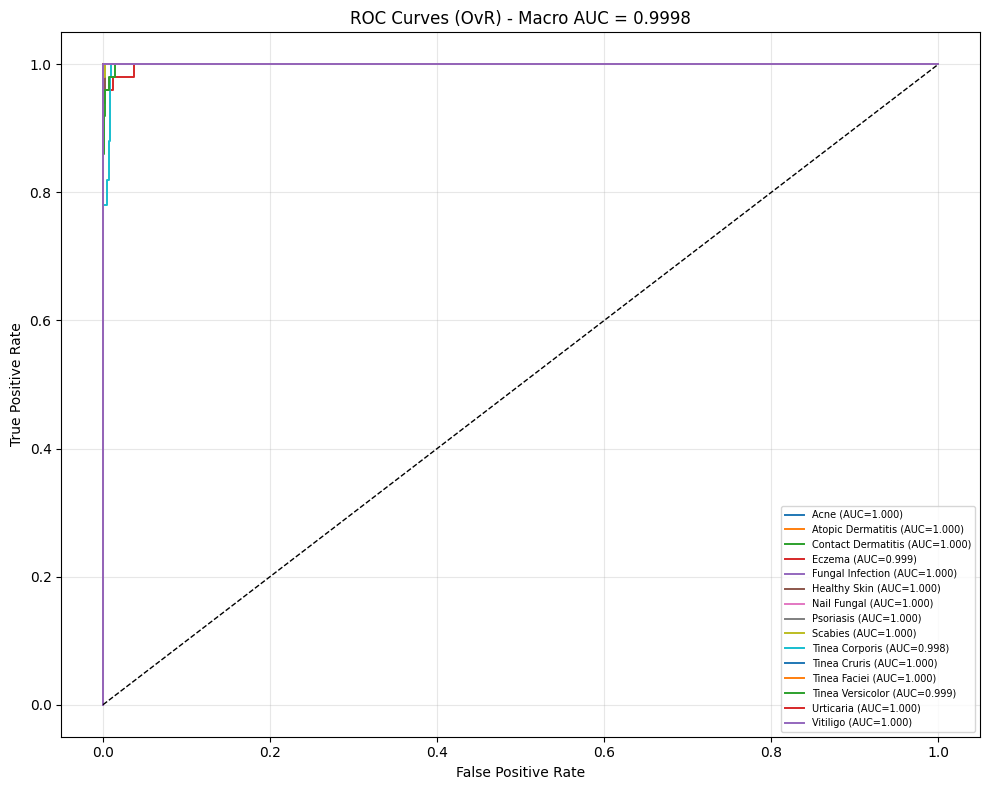

✅ Macro AUC: 0.9998 | Weighted AUC: 0.9998


,class,AUC
0,Acne,1.0000
1,Atopic Dermatitis,1.0000
2,Contact Dermatitis,1.0000
3,Eczema,0.9990
4,Fungal Infection,1.0000
5,Healthy Skin,0.9998
6,Nail Fungal,1.0000
7,Psoriasis,1.0000
8,Scabies,0.9999
9,Tinea Corporis,0.9983


In [32]:
# ============================================================
# 📉 CELL 23 — ROC curve + AUC (one-vs-rest, per class)
# ============================================================
y_bin = label_binarize(test_gts, classes=list(range(NB_CLASSES)))
macro_auc = roc_auc_score(y_bin, test_probs, average="macro", multi_class="ovr")
weighted_auc = roc_auc_score(y_bin, test_probs, average="weighted", multi_class="ovr")

plt.figure(figsize=(10, 8))
auc_rows = []
for i, cname in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], test_probs[:, i])
    a = auc(fpr, tpr)
    auc_rows.append({"class": cname, "AUC": round(a, 4)})
    plt.plot(fpr, tpr, lw=1.4, label=f"{cname} (AUC={a:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC Curves (OvR) - Macro AUC = {macro_auc:.4f}")
plt.legend(fontsize=7, loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(MODEL_DIR, "roc_curves.png"), dpi=150)
plt.show()

auc_df = pd.DataFrame(auc_rows)
auc_df.to_csv(os.path.join(MODEL_DIR, "per_class_auc.csv"), index=False)
print(f"✅ Macro AUC: {macro_auc:.4f} | Weighted AUC: {weighted_auc:.4f}")
display(auc_df)

Extracting features:   0%|          | 0/47 [00:00<?, ?it/s]

✅ Embedding shape: (750, 512)


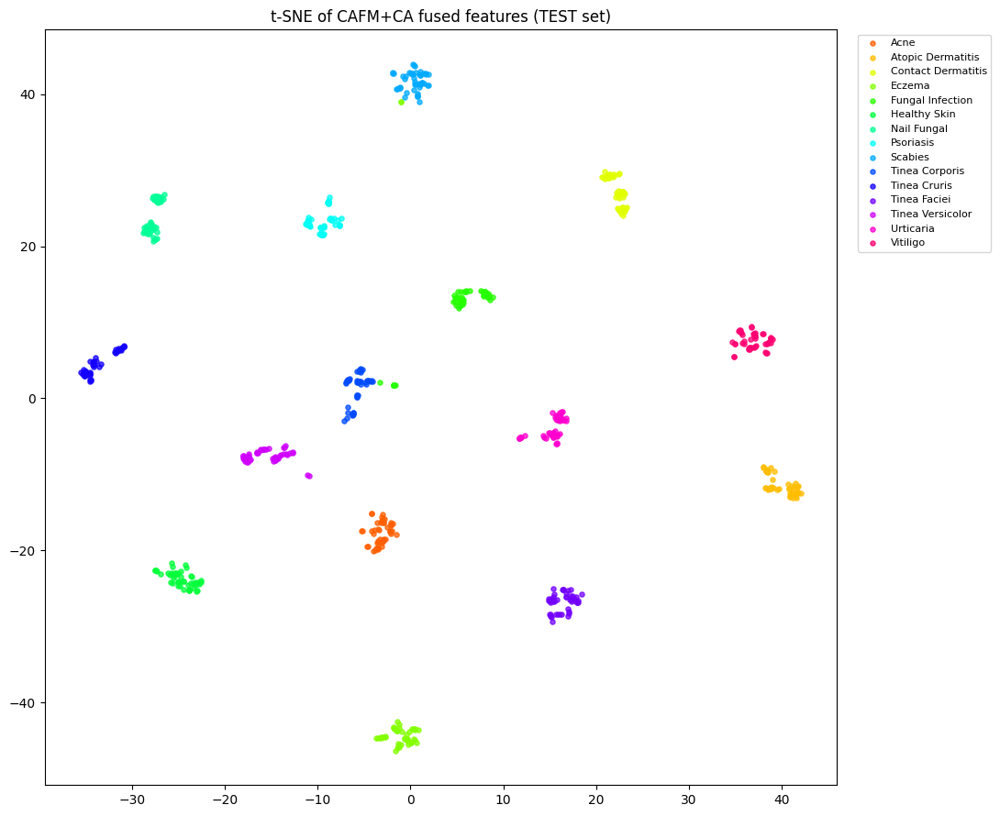

In [33]:
# ============================================================
# 🌀 CELL 24 — t-SNE of fused 512-d features (feature separability)
# ============================================================
@torch.no_grad()
def extract_embeddings(loader):
    model.eval()
    embs, labs = [], []
    for imgs, labels in tqdm(loader, desc="Extracting features", leave=False):
        imgs = imgs.to(device)
        with amp_ctx():
            e = model.embed(imgs)
        embs.append(e.float().cpu()); labs.append(labels)
    return torch.cat(embs).numpy(), torch.cat(labs).numpy()

emb, lab = extract_embeddings(test_loader)
print("✅ Embedding shape:", emb.shape)

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED)
emb2d = tsne.fit_transform(emb)

plt.figure(figsize=(11, 9))
palette = sn.color_palette("hsv", NB_CLASSES)
for i, cname in enumerate(CLASS_NAMES):
    m = lab == i
    plt.scatter(emb2d[m, 0], emb2d[m, 1], s=14, color=palette[i], label=cname, alpha=0.75)
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("t-SNE of CAFM+CA fused features (TEST set)")
plt.tight_layout(); plt.savefig(os.path.join(MODEL_DIR, "tsne_features.png"), dpi=150)
plt.show()

## 🔍 Explainability (XAI)

চারটা ভিউ দেখানো হচ্ছে:

1. **Grad-CAM / Grad-CAM++ (DenseNet branch)** target layer = শেষ dense block (`features.norm5`)
2. **Grad-CAM / Grad-CAM++ (Swin branch)** target layer = শেষ stage এর layernorm (reshape_transform সহ)
3. **Fused CAM** দুই ব্রাঞ্চের হিটম্যাপ overlay/average, অর্থাৎ CAFM এর পর মডেল আসলে কোথায় তাকায়
4. **CAFM cross-attention map** DenseNet query গুলো Swin এর কোন গ্লোবাল অঞ্চলে attend করছে

In [34]:
# ============================================================
# 🔍 CELL 25 — Grad-CAM / Grad-CAM++ setup (দুই ব্রাঞ্চের জন্য আলাদা)
# ============================================================
def swin_reshape_transform(tensor):
    # HF Swin last_hidden_state: (B, 49, 768) -> (B, 768, 7, 7)
    B, N, C = tensor.shape
    hw = int(math.sqrt(N))
    return tensor.reshape(B, hw, hw, C).permute(0, 3, 1, 2)

cnn_target_layers   = [model.cnn_branch.features.norm5]              # DenseNet শেষ dense block
swin_target_layers  = [model.swin_branch.backbone.layernorm]         # Swin শেষ stage
fused_target_layers = [model.coord_att]                              # CAFM + CA এর আউটপুট

def build_cam(cls, layers, reshape=None):
    try:
        return cls(model=model, target_layers=layers, reshape_transform=reshape)
    except TypeError:   # পুরনো grad-cam ভার্সন
        return cls(model=model, target_layers=layers, reshape_transform=reshape,
                   use_cuda=torch.cuda.is_available())

cam_cnn    = build_cam(GradCAM,         cnn_target_layers)
cam_cnn_pp = build_cam(GradCAMPlusPlus, cnn_target_layers)
cam_swin    = build_cam(GradCAM,         swin_target_layers, swin_reshape_transform)
cam_swin_pp = build_cam(GradCAMPlusPlus, swin_target_layers, swin_reshape_transform)
cam_fused    = build_cam(GradCAM,         fused_target_layers)
cam_fused_pp = build_cam(GradCAMPlusPlus, fused_target_layers)

print("✅ Grad-CAM ও Grad-CAM++ রেডি (DenseNet branch, Swin branch, Fused)")

✅ Grad-CAM ও Grad-CAM++ রেডি (DenseNet branch, Swin branch, Fused)


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:897.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


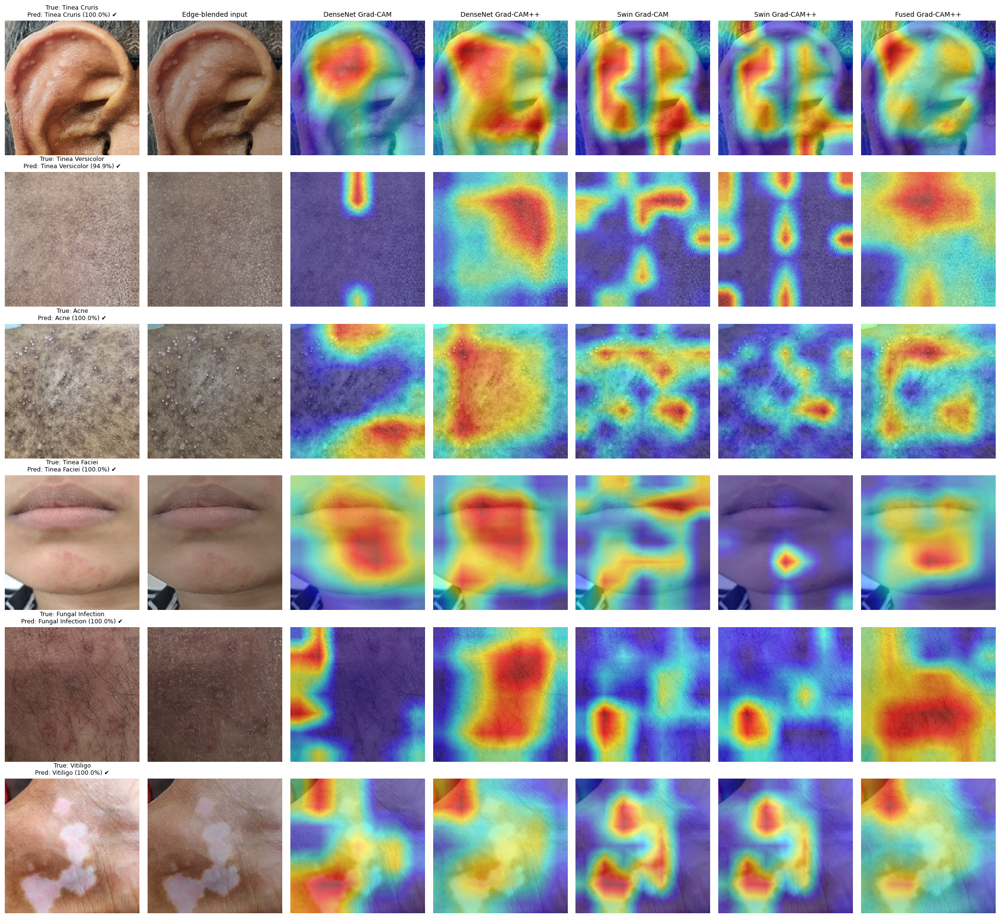

In [35]:
# ============================================================
# 🖼️ CELL 26 — XAI VISUALIZATION (sample test images)
# ============================================================
N_XAI = 6
idxs = random.sample(range(len(test_dataset)), min(N_XAI, len(test_dataset)))

def cam_on(cam_obj, input_tensor, cls_idx):
    grayscale = cam_obj(input_tensor=input_tensor,
                        targets=[ClassifierOutputTarget(cls_idx)])[0]
    return grayscale

cols = ["Input (raw)", "Edge-blended input", "DenseNet Grad-CAM", "DenseNet Grad-CAM++",
        "Swin Grad-CAM", "Swin Grad-CAM++", "Fused Grad-CAM++"]
fig, axes = plt.subplots(len(idxs), len(cols), figsize=(3.0 * len(cols), 3.2 * len(idxs)))
axes = np.atleast_2d(axes)

model.eval()
for r, di in enumerate(idxs):
    img_t, true_lab = test_dataset[di]
    input_tensor = img_t.unsqueeze(0).to(device)
    rgb = img_t.permute(1, 2, 0).cpu().numpy()                      # [0,1] raw

    with torch.no_grad():
        probs = F.softmax(model(input_tensor).float(), dim=1)[0]
        pred = int(probs.argmax()); conf = float(probs[pred])
        _, blended, _ = model.edge_input(input_tensor, return_parts=True)
    blended_np = blended[0].permute(1, 2, 0).cpu().numpy()

    maps = [cam_on(cam_cnn, input_tensor, pred),
            cam_on(cam_cnn_pp, input_tensor, pred),
            cam_on(cam_swin, input_tensor, pred),
            cam_on(cam_swin_pp, input_tensor, pred),
            cam_on(cam_fused_pp, input_tensor, pred)]

    panels = [rgb, np.clip(blended_np, 0, 1)] + [show_cam_on_image(rgb, m, use_rgb=True) for m in maps]
    for c, (panel, title) in enumerate(zip(panels, cols)):
        axes[r, c].imshow(panel); axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(title, fontsize=10)
    ok = "✔" if pred == true_lab else "✘"
    axes[r, 0].set_title(f"True: {CLASS_NAMES[true_lab]}\nPred: {CLASS_NAMES[pred]} ({conf*100:.1f}%) {ok}",
                         fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "xai_gradcam_all_branches.png"), dpi=150)
plt.show()

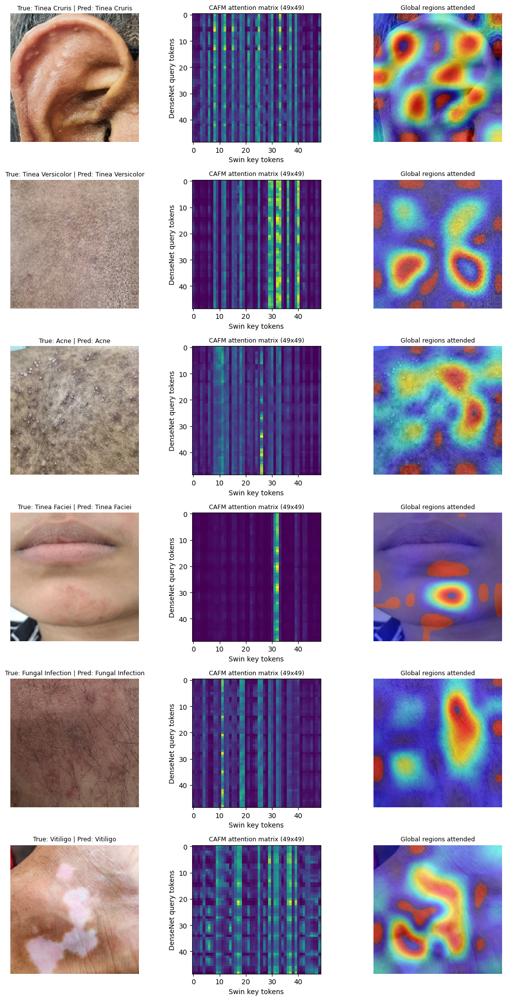

In [36]:
# ============================================================
# 🧠 CELL 27 — CAFM Cross-Attention Map (Q=DenseNet -> K,V=Swin)
# ============================================================
model.cafm.return_attn = True
fig, axes = plt.subplots(len(idxs), 3, figsize=(11, 3.4 * len(idxs)))
axes = np.atleast_2d(axes)

for r, di in enumerate(idxs):
    img_t, true_lab = test_dataset[di]
    input_tensor = img_t.unsqueeze(0).to(device)
    rgb = img_t.permute(1, 2, 0).cpu().numpy()
    with torch.no_grad():
        logits = model(input_tensor)
        pred = int(logits.argmax(1))
    attn = model.cafm.attn_weights[0].float().cpu().numpy()      # 49x49
    key_imp = attn.mean(axis=0).reshape(7, 7)                    # গড় attention প্রতি global অঞ্চলে
    key_imp = (key_imp - key_imp.min()) / (key_imp.max() - key_imp.min() + 1e-8)
    key_up = cv2.resize(key_imp, (IMG_DIM, IMG_DIM), interpolation=cv2.INTER_CUBIC)

    axes[r, 0].imshow(rgb); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"True: {CLASS_NAMES[true_lab]} | Pred: {CLASS_NAMES[pred]}", fontsize=9)
    im = axes[r, 1].imshow(attn, cmap="viridis")
    axes[r, 1].set_title("CAFM attention matrix (49x49)", fontsize=9)
    axes[r, 1].set_xlabel("Swin key tokens"); axes[r, 1].set_ylabel("DenseNet query tokens")
    axes[r, 2].imshow(show_cam_on_image(rgb, key_up, use_rgb=True)); axes[r, 2].axis("off")
    axes[r, 2].set_title("Global regions attended", fontsize=9)

model.cafm.return_attn = False
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "xai_cafm_attention.png"), dpi=150)
plt.show()

✅ মোট 16টা misclassified image পাওয়া গেছে


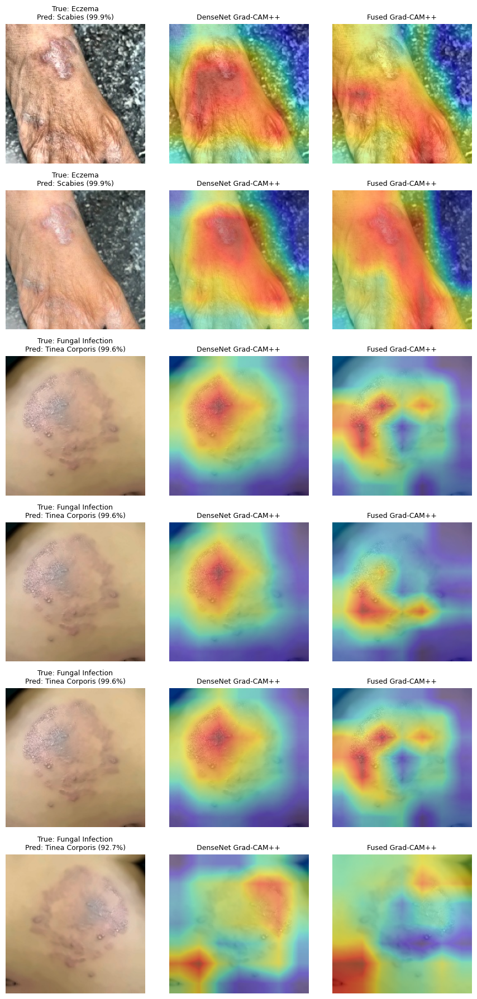

,filename,true_class,pred_class,confidence
0,AUG_0022.jpg,Eczema,Scabies,0.9993
1,ORIG_0010.jpg,Eczema,Scabies,0.9992
2,AUG_0016.jpg,Fungal Infection,Tinea Corporis,0.9960
3,AUG_0020.jpg,Fungal Infection,Tinea Corporis,0.9955
4,AUG_0022.jpg,Fungal Infection,Tinea Corporis,0.9960
5,AUG_0023.jpg,Fungal Infection,Tinea Corporis,0.9274
6,AUG_0025.jpg,Fungal Infection,Tinea Corporis,0.9889
7,AUG_0044.jpg,Fungal Infection,Tinea Corporis,0.9905
8,AUG_0003.jpg,Tinea Corporis,Acne,0.5343
9,AUG_0018.jpg,Tinea Corporis,Acne,0.4462


In [37]:
# ============================================================
# 🔍 Misclassified Case Study — actual error গুলো Grad-CAM সহ visualize
# ============================================================
mis_idxs = [i for i in range(len(test_gts)) if test_gts[i] != test_preds[i]]
print(f"✅ মোট {len(mis_idxs)}টা misclassified image পাওয়া গেছে")

N_SHOW = min(6, len(mis_idxs))          # কয়টা কেস দেখাবেন
show_idxs = mis_idxs[:N_SHOW]

fig, axes = plt.subplots(N_SHOW, 3, figsize=(9, 3 * N_SHOW))
if N_SHOW == 1:
    axes = axes.reshape(1, -1)

model.eval()
for row, di in enumerate(show_idxs):
    img_t, true_lab = test_dataset[di]
    input_tensor = img_t.unsqueeze(0).to(device)
    pred_lab = test_preds[di]
    conf = test_probs[di, pred_lab]

    rgb01 = img_t.permute(1, 2, 0).cpu().numpy()
    rgb_uint8 = (np.clip(rgb01, 0, 1) * 255).astype(np.uint8)

    axes[row, 0].imshow(rgb_uint8)
    axes[row, 0].set_title(f"True: {CLASS_NAMES[true_lab]}\nPred: {CLASS_NAMES[pred_lab]} ({conf*100:.1f}%)",
                            fontsize=9)
    axes[row, 0].axis("off")

    cam_d = cam_on(cam_cnn_pp, input_tensor, pred_lab)
    axes[row, 1].imshow(rgb_uint8); axes[row, 1].imshow(cam_d, cmap="jet", alpha=0.45)
    axes[row, 1].set_title("DenseNet Grad-CAM++", fontsize=9); axes[row, 1].axis("off")

    cam_f = cam_on(cam_fused_pp, input_tensor, pred_lab)
    axes[row, 2].imshow(rgb_uint8); axes[row, 2].imshow(cam_f, cmap="jet", alpha=0.45)
    axes[row, 2].set_title("Fused Grad-CAM++", fontsize=9); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "misclassified_case_study.png"), dpi=200, bbox_inches="tight")
plt.show()

mis_df = pd.DataFrame([{
    "filename": os.path.basename(test_dataset.samples[i][0]),
    "true_class": CLASS_NAMES[test_gts[i]],
    "pred_class": CLASS_NAMES[test_preds[i]],
    "confidence": round(float(test_probs[i, test_preds[i]]), 4),
} for i in mis_idxs])
mis_df.to_csv(os.path.join(MODEL_DIR, "misclassified_summary.csv"), index=False)
display(mis_df)

In [ ]:
# ============================================================
# 🧪 Ablation Study — 6 architectural variants
# ============================================================
class AblationModel(nn.Module):
    """variant অনুযায়ী branch/fusion/attention on-off করে ভিন্ন architecture বানায়।
    variant options: 'a_densenet_only', 'b_swin_only', 'c_concat_fusion',
                      'd_no_coord_attn', 'e_no_edge_input', 'f_full_proposed'"""
    def __init__(self, variant, num_classes,
                 embed_dim=EMBED_DIM, num_heads=NUM_HEADS, ca_reduction=CA_REDUCTION,
                 dropout=DROPOUT, head_hidden=HEAD_HIDDEN,
                 freeze_cnn_first_n=FREEZE_CNN_FIRST_N, freeze_swin_stages=FREEZE_SWIN_STAGES):
        super().__init__()
        self.variant = variant
        edge_alpha = 1.0 if variant == "e_no_edge_input" else EDGE_ALPHA   # alpha=1.0 -> raw only, no edge blend
        self.edge_input = EdgeFusionInput(mode=EDGE_MODE, alpha=edge_alpha)

        self.use_cnn  = variant != "b_swin_only"
        self.use_swin = variant != "a_densenet_only"
        if self.use_cnn:
            self.cnn_branch = DenseNetBranch(freeze_first_n=freeze_cnn_first_n)
        if self.use_swin:
            self.swin_branch = SwinBranch(freeze_stages=freeze_swin_stages)

        if variant in ("f_full_proposed", "e_no_edge_input", "d_no_coord_attn"):
            self.cafm = CrossAttentionFusion(self.cnn_branch.out_channels,
                                             self.swin_branch.out_channels,
                                             embed_dim=embed_dim, num_heads=num_heads)
            fused_dim = embed_dim
        elif variant == "c_concat_fusion":
            # CAFM-এর বদলে simple channel-concat + 1x1 conv projection (no cross-attention)
            self.concat_proj = nn.Sequential(
                nn.Conv2d(self.cnn_branch.out_channels + self.swin_branch.out_channels, embed_dim,
                          kernel_size=1, bias=False),
                nn.BatchNorm2d(embed_dim), nn.GELU())
            fused_dim = embed_dim
        elif variant == "a_densenet_only":
            fused_dim = self.cnn_branch.out_channels
        elif variant == "b_swin_only":
            fused_dim = self.swin_branch.out_channels

        self.coord_att = (CoordinateAttention(fused_dim, reduction=ca_reduction)
                           if variant != "d_no_coord_attn" else nn.Identity())

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(fused_dim, head_hidden), nn.BatchNorm1d(head_hidden), HSwish(),
            nn.Dropout(dropout * 0.5), nn.Linear(head_hidden, num_classes))

    def forward_features(self, x):
        x = self.edge_input(x)
        if self.variant == "a_densenet_only":
            f = self.cnn_branch(x)
        elif self.variant == "b_swin_only":
            f = self.swin_branch(x)
        elif self.variant == "c_concat_fusion":
            f = self.concat_proj(torch.cat([self.cnn_branch(x), self.swin_branch(x)], dim=1))
        else:  # f_full_proposed, e_no_edge_input, d_no_coord_attn -> CAFM ব্যবহার করে
            f = self.cafm(self.cnn_branch(x), self.swin_branch(x))
        return self.coord_att(f)

    def forward(self, x):
        return self.classifier(self.pool(self.forward_features(x)))

    def freeze_backbones(self):
        if self.use_cnn:  self.cnn_branch.freeze_all()
        if self.use_swin: self.swin_branch.freeze_all()

    def unfreeze_for_finetune(self, cnn_first_n=FREEZE_CNN_FIRST_N, swin_stages=FREEZE_SWIN_STAGES):
        if self.use_cnn:  self.cnn_branch.freeze_first_n(cnn_first_n)
        if self.use_swin: self.swin_branch.freeze_stages(swin_stages)


# ============================================================
# 🧪 Ablation training loop — সবগুলো variant একে একে ট্রেইন করে TEST acc/F1 নেয়
# ============================================================
ABLATION_VARIANTS = ["a_densenet_only", "b_swin_only", "c_concat_fusion",
                     "d_no_coord_attn", "e_no_edge_input", "f_full_proposed"]
ABL_EPOCHS_P1 = 8     # সময় বাঁচাতে মূল ১০ থেকে সামান্য কমানো — চাইলে EPOCHS_P1 বসান
ABL_EPOCHS_P2 = 20    # সময় বাঁচাতে মূল ২৫-৩৫ থেকে কমানো — চাইলে EPOCHS_P2 বসান

ablation_results = []
for variant in ABLATION_VARIANTS:
    print("\n" + "=" * 70)
    print(f"🧪 ABLATION VARIANT: {variant}")
    print("=" * 70)

    torch.manual_seed(SEED)
    abl_model = AblationModel(variant, NB_CLASSES).to(device)
    abl_ckpt_path = os.path.join(MODEL_DIR, f"ablation_{variant}_best.pt")
    abl_criterion = HybridLoss(class_weights=class_weights_tensor if USE_CLASS_WEIGHTS else None)

    # ---- Phase 1 ----
    abl_model.freeze_backbones()
    p1_params = [p for p in abl_model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(p1_params, lr=LR_P1, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ABL_EPOCHS_P1, eta_min=ETA_MIN)
    stopper = EarlyStopping(patience=5, mode="max")
    best_f1 = -1.0
    for ep in range(1, ABL_EPOCHS_P1 + 1):
        train_one_epoch(abl_model, train_loader, opt, abl_criterion, f"{variant} P1 {ep}/{ABL_EPOCHS_P1}")
        _, va_acc, va_f1 = evaluate(abl_model, val_loader, abl_criterion)
        sch.step()
        if stopper.step(va_f1) and va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": abl_model.state_dict()}, abl_ckpt_path)
        if stopper.stop:
            break

    ckpt = torch.load(abl_ckpt_path, map_location=device)
    abl_model.load_state_dict(ckpt["model"])

    # ---- Phase 2 ----
    abl_model.unfreeze_for_finetune(FREEZE_CNN_FIRST_N, FREEZE_SWIN_STAGES)
    backbone_p, new_p = [], []
    for n_, p in abl_model.named_parameters():
        if not p.requires_grad:
            continue
        (backbone_p if (n_.startswith("cnn_branch") or n_.startswith("swin_branch")) else new_p).append(p)
    param_groups = [{"params": new_p, "lr": LR_HEAD_P2}]
    if backbone_p:
        param_groups.append({"params": backbone_p, "lr": LR_BACKBONE})
    opt = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ABL_EPOCHS_P2, eta_min=ETA_MIN)
    stopper = EarlyStopping(patience=8, mode="max")
    for ep in range(1, ABL_EPOCHS_P2 + 1):
        train_one_epoch(abl_model, train_loader, opt, abl_criterion, f"{variant} P2 {ep}/{ABL_EPOCHS_P2}")
        _, va_acc, va_f1 = evaluate(abl_model, val_loader, abl_criterion)
        sch.step()
        if stopper.step(va_f1) and va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": abl_model.state_dict()}, abl_ckpt_path)
        if stopper.stop:
            break

    ckpt = torch.load(abl_ckpt_path, map_location=device)
    abl_model.load_state_dict(ckpt["model"])

    # ---- test evaluation ----
    _, te_acc, te_f1, te_gts, te_preds, te_probs = evaluate(
        abl_model, test_loader, abl_criterion, return_preds=True, return_probs=True)
    y_bin = label_binarize(te_gts, classes=list(range(NB_CLASSES)))
    te_auc = roc_auc_score(y_bin, te_probs, average="macro", multi_class="ovr")

    n_params = sum(p.numel() for p in abl_model.parameters())
    ablation_results.append({"variant": variant, "test_accuracy": te_acc, "test_macro_f1": te_f1,
                              "test_macro_auc": te_auc, "n_params": n_params})
    print(f"✅ {variant}: Acc={te_acc*100:.2f}% F1={te_f1*100:.2f}% AUC={te_auc:.4f} Params={n_params:,}")

    del abl_model
    torch.cuda.empty_cache()

ablation_df = pd.DataFrame(ablation_results)
ablation_df.to_csv(os.path.join(MODEL_DIR, "ablation_results.csv"), index=False)
print("\n" + "=" * 70)
print("📊 ABLATION STUDY SUMMARY")
print("=" * 70)
display(ablation_df)


🧪 ABLATION VARIANT: a_densenet_only
   DenseNet201: প্রথম 100/401 leaf layer frozen | trainable 16,215,616/18,092,928


a_densenet_only P1 1/8:   0%|          | 0/375 [00:00<?, ?it/s]

a_densenet_only P1 2/8:   0%|          | 0/375 [00:00<?, ?it/s]

a_densenet_only P1 3/8:   0%|          | 0/375 [00:00<?, ?it/s]

a_densenet_only P1 4/8:   0%|          | 0/375 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cee369e18a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cee369e18a0>
  Traceback (most recent call last):
   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
       self._shutdown_workers() 
^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^    if w.is_alive():^
^^  ^ ^ ^  ^^ ^^
^  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
^^    ^assert self._parent_pid == os.getpid(), 'can only test a child process'
^  ^^ ^ ^ ^ ^ 
   File "/usr/li

... (82 outputs left out)

b_swin_only P2 14/20:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


b_swin_only P2 15/20:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cee369e18a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/pro

In [ ]:
# ============================================================
# ⏱️ CELL 29 — Model complexity & inference speed (paper এর Table)
# ============================================================
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
size_mb = total_params * 4 / (1024 ** 2)

model.eval()
dummy = torch.rand(1, 3, IMG_DIM, IMG_DIM, device=device)
with torch.no_grad():
    for _ in range(10):
        model(dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(50):
        model(dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    ms = (time.time() - t0) / 50 * 1000

complexity = pd.DataFrame([{
    "Total params (M)": round(total_params / 1e6, 2),
    "Trainable params (M)": round(trainable_params / 1e6, 2),
    "Model size (MB, fp32)": round(size_mb, 1),
    "Inference / image (ms)": round(ms, 2),
    "Throughput (img/s)": round(1000 / ms, 1),
}])
complexity.to_csv(os.path.join(MODEL_DIR, "model_complexity.csv"), index=False)
display(complexity)

In [ ]:
# ============================================================
# 💾 CELL 30 — Save model + zip সব রেজাল্ট
# ============================================================
torch.save({"model": model.state_dict(),
            "class_names": CLASS_NAMES,
            "config": {"img_dim": IMG_DIM, "embed_dim": EMBED_DIM, "num_heads": NUM_HEADS,
                       "edge_mode": EDGE_MODE, "edge_alpha": EDGE_ALPHA,
                       "swin_ckpt": SWIN_CKPT}},
           os.path.join(MODEL_DIR, f"{MODEL_NAME}_final.pt"))
print("✅ Final model saved")

results_zip = os.path.join(WORKING_DIR, f"{MODEL_NAME}_results.zip")
with zipfile.ZipFile(results_zip, "w") as zf:
    for fname in ["sample_dataset.png", "edge_enhancement_preview.png",
                  f"{MODEL_NAME}_metrics.png", "confusion_matrix.png",
                  "per_class_error_analysis.png", "per_class_error_summary.csv",
                  "roc_curves.png", "per_class_auc.csv", "tsne_features.png",
                  "xai_gradcam_all_branches.png", "xai_cafm_attention.png",
                  "final_test_classification_report.txt", "comparison_with_baselines.csv",
                  "model_complexity.csv", "history.json"]:
        fp = os.path.join(MODEL_DIR, fname)
        if os.path.exists(fp):
            zf.write(fp, arcname=fname)
print(f"✅ Results zipped: {results_zip}")
display(FileLink(results_zip))

# External validation

In [ ]:
# ============================================================
# 🔍 STEP 0 — Kaggle-এ exact mounted path কনফার্ম করা
#    (আগে এটা একবার চালাও, তারপর নিচের SKINDISNET_DIR ঠিক করে নাও)
# ============================================================
import os

for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 3:
        print("  " * depth + f"📁 {os.path.basename(root)}/  ({len(dirs)} folders, {len(files)} files)")
    if depth >= 3:
        dirs[:] = []


# ============================================================
# 🌍 STEP 1 — Helper: external dataset evaluate করার generic ফাংশন
#    (retraining নেই — শুধু আগে থেকে ট্রেইন করা `model` দিয়ে inference)
# ============================================================
class PathListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label


def evaluate_external_dataset(dataset_name, root_dir, class_map, model, class_names):
    """
    dataset_name : রিপোর্টে দেখানোর নাম, যেমন 'SkinDisNet'
    root_dir     : external dataset-এর root folder (ভেতরে class-name subfolder)
    class_map    : {external_folder_name: internal_class_name}
    """
    samples = []
    for ext_class, internal_class in class_map.items():
        class_dir = os.path.join(root_dir, ext_class)
        if not os.path.isdir(class_dir):
            print(f"  ⚠️ পাওয়া যায়নি, skip: {class_dir}")
            continue
        internal_idx = class_names.index(internal_class)
        imgs = [f for f in os.listdir(class_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        samples += [(os.path.join(class_dir, f), internal_idx) for f in imgs]
        print(f"  ✅ {ext_class:30s} -> {internal_class:20s} ({len(imgs)} images)")

    if len(samples) == 0:
        print(f"  ❌ {dataset_name}: কোনো sample পাওয়া যায়নি")
        return None

    ds = PathListDataset(samples, eval_transform)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

    criterion_eval = HybridLoss(class_weights=None)
    _, acc, f1, gts, preds, probs = evaluate(model, loader, criterion_eval,
                                              return_preds=True, return_probs=True)

    present = sorted(set(gts))
    present_names = [class_names[i] for i in present]

    print(f"\n{'='*70}\n🌍 {dataset_name} — External Validation (n={len(gts)})\n{'='*70}")
    print(f"Accuracy : {acc*100:.2f}%   Macro F1 : {f1*100:.2f}%")
    print(classification_report(gts, preds, labels=present, target_names=present_names,
                                 digits=4, zero_division=0))

    cm = confusion_matrix(gts, preds, labels=present)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
                xticklabels=present_names, yticklabels=present_names)
    plt.title(f"{dataset_name} — Confusion Matrix (External Validation)")
    plt.xlabel("Predicted label"); plt.ylabel("True label")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    safe_name = dataset_name.lower().replace(" ", "_")
    plt.savefig(os.path.join(MODEL_DIR, f"external_{safe_name}_confmat.png"), dpi=300, bbox_inches="tight")
    plt.show()

    return {"dataset": dataset_name, "n_samples": len(gts), "n_classes": len(present),
            "accuracy": acc, "macro_f1": f1}


# ============================================================
# 🌍 STEP 2 — SkinDisNet external validation
# ============================================================
# 👇 STEP 0-এর আউটপুট দেখে এই path-টা কনফার্ম/ঠিক করো
SKINDISNET_DIR = "/kaggle/input/datasets/saoum123/secondary-balance/Secondary Balance"   # 👈 এখানে বসাও

# 👇 তোমার আসলে upload করা folder-name অনুযায়ী (screenshot থেকে, underscore সহ)
SKINDISNET_CLASS_MAP = {
    "Atopic_Dermatitis_AD":  "Atopic Dermatitis",
    "Contact_Dermatitis_CD": "Contact Dermatitis",
    "Eczema_EC":              "Eczema",
    "Scabies_SC":              "Scabies",
    "Tinea_Corporis_TC":      "Tinea Corporis",
}

result_skindisnet = evaluate_external_dataset(
    "SkinDisNet", SKINDISNET_DIR, SKINDISNET_CLASS_MAP, model, CLASS_NAMES)


# ============================================================
# 🌍 STEP 3 — Internal vs External তুলনা টেবিল
# ============================================================
all_results = [
    {"dataset": "Internal TEST (own split)", "n_samples": len(test_gts),
     "n_classes": NB_CLASSES, "accuracy": test_acc, "macro_f1": test_f1},  # Cell 20-এর ভেরিয়েবল
]
if result_skindisnet is not None:
    all_results.append(result_skindisnet)

comparison_df = pd.DataFrame(all_results)
comparison_df["accuracy_%"] = (comparison_df["accuracy"] * 100).round(2)
comparison_df["macro_f1_%"] = (comparison_df["macro_f1"] * 100).round(2)
comparison_df["gap_vs_internal_pp"] = (
    (comparison_df.loc[0, "accuracy"] - comparison_df["accuracy"]) * 100
).round(2)

comparison_df.to_csv(os.path.join(MODEL_DIR, "external_validation_comparison.csv"), index=False)
print("\n" + "=" * 70)
print("📊 INTERNAL vs EXTERNAL VALIDATION — SUMMARY")
print("=" * 70)
display(comparison_df[["dataset", "n_samples", "n_classes", "accuracy_%", "macro_f1_%", "gap_vs_internal_pp"]])

# K fold Code


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
# এই ফাইলটা আলাদা আলাদা CELL হিসেবে Kaggle/Colab নোটবুকে (CELL 36 এর পরে) পেস্ট করুন।
# প্রতিটা "# %% ADD-ON n" এর নিচের অংশ একটা আলাদা cell হিসেবে চালাবেন।
# নির্ভরতা: CELL 1–36 আগে চালানো থাকতে হবে (model classes, all_paths, all_labels,
#           skf, K_FOLDS, KFOLD_SEED, KFOLD_EPOCHS_P1/P2, MODEL_DIR, CLASS_NAMES ইত্যাদি)
# ══════════════════════════════════════════════════════════════════════════

# %% ADD-ON 1 — Generalized, reusable K-Fold runner (predictions + per-class report সহ)
# ============================================================
# 🔁 ADD-ON 1 — Reusable K-Fold runner for ANY model (hybrid বা baseline)
#    আগের CELL 36 এর লজিককেই generic ফাংশনে রূপান্তর করা হলো, যাতে
#    বেসলাইন মডেলগুলোও (DenseNet-only, Swin-only) *একই* fold split-এ
#    train/evaluate করা যায় — fair, apples-to-apples comparison-এর জন্য এটা must।
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from scipy import stats as sstats
from scipy.stats import ttest_rel, wilcoxon

def run_kfold_for_model(model_builder, model_tag, all_paths, all_labels, skf,
                         epochs_p1=KFOLD_EPOCHS_P1, epochs_p2=KFOLD_EPOCHS_P2,
                         seed=KFOLD_SEED):
    """
    model_builder : fn() -> নতুন, untrained model instance (already .to(device))
                     e.g. lambda: HybridDenseSwinCAFM(NB_CLASSES).to(device)
                     e.g. lambda: AblationModel("a_densenet_only", NB_CLASSES).to(device)
    রিটার্ন করে: (results_df, all_fold_preds) — যেখানে all_fold_preds হলো
                 প্রতি fold-এর (gts, preds, probs) এর লিস্ট — confusion matrix ও
                 per-class report বানানোর জন্য পরে দরকার হবে।
    """
    results = []
    all_fold_preds = []

    for fold, (trainval_idx, test_idx) in enumerate(skf.split(all_paths, all_labels), start=1):
        print(f"\n{'='*70}\n🔁 [{model_tag}] FOLD {fold}/{K_FOLDS}\n{'='*70}")

        tr_idx, va_idx = train_test_split(
            trainval_idx, test_size=0.1, stratify=all_labels[trainval_idx], random_state=seed)

        fold_train_ds = PathListDataset(all_paths[tr_idx], all_labels[tr_idx], train_transform)
        fold_val_ds   = PathListDataset(all_paths[va_idx], all_labels[va_idx], eval_transform)
        fold_test_ds  = PathListDataset(all_paths[test_idx], all_labels[test_idx], eval_transform)

        fold_train_loader = DataLoader(fold_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
        fold_val_loader   = DataLoader(fold_val_ds, batch_size=BATCH_SIZE, shuffle=False,
                                        num_workers=NUM_WORKERS, pin_memory=True)
        fold_test_loader  = DataLoader(fold_test_ds, batch_size=BATCH_SIZE, shuffle=False,
                                        num_workers=NUM_WORKERS, pin_memory=True)

        y_fold_train = all_labels[tr_idx]
        w_np = class_weight.compute_class_weight(class_weight="balanced",
                                                  classes=np.unique(y_fold_train), y=y_fold_train)
        w_tensor = torch.tensor(w_np, dtype=torch.float32).to(device)
        fold_criterion = HybridLoss(class_weights=w_tensor if USE_CLASS_WEIGHTS else None)

        torch.manual_seed(seed + fold)
        fold_model = model_builder()
        fold_ckpt_path = os.path.join(MODEL_DIR, f"kfold_{model_tag}_{fold}_best.pt")

        # ---- Phase 1: backbone(s) frozen ----
        if hasattr(fold_model, "freeze_backbones"):
            fold_model.freeze_backbones()
        p1_params = [p for p in fold_model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(p1_params, lr=LR_P1, weight_decay=WEIGHT_DECAY)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs_p1, eta_min=ETA_MIN)
        stopper = EarlyStopping(patience=5, mode="max")
        best_f1 = -1.0
        for ep in range(1, epochs_p1 + 1):
            train_one_epoch(fold_model, fold_train_loader, opt, fold_criterion,
                             f"[{model_tag}] Fold{fold} P1 {ep}/{epochs_p1}")
            _, va_acc, va_f1 = evaluate(fold_model, fold_val_loader, fold_criterion)
            sch.step()
            improved = stopper.step(va_f1)
            if improved and va_f1 > best_f1:
                best_f1 = va_f1
                torch.save({"model": fold_model.state_dict()}, fold_ckpt_path)
            if stopper.stop:
                break

        ckpt = torch.load(fold_ckpt_path, map_location=device)
        fold_model.load_state_dict(ckpt["model"])

        # ---- Phase 2: fine-tuning ----
        if hasattr(fold_model, "unfreeze_for_finetune"):
            fold_model.unfreeze_for_finetune(FREEZE_CNN_FIRST_N, FREEZE_SWIN_STAGES)
        backbone_p, new_p = [], []
        for n_, p in fold_model.named_parameters():
            if not p.requires_grad:
                continue
            (backbone_p if (n_.startswith("cnn_branch") or n_.startswith("swin_branch")) else new_p).append(p)
        opt = torch.optim.AdamW(
            [{"params": backbone_p, "lr": LR_BACKBONE}, {"params": new_p, "lr": LR_HEAD_P2}],
            weight_decay=WEIGHT_DECAY)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs_p2, eta_min=ETA_MIN)
        stopper = EarlyStopping(patience=8, mode="max")
        for ep in range(1, epochs_p2 + 1):
            train_one_epoch(fold_model, fold_train_loader, opt, fold_criterion,
                             f"[{model_tag}] Fold{fold} P2 {ep}/{epochs_p2}")
            _, va_acc, va_f1 = evaluate(fold_model, fold_val_loader, fold_criterion)
            sch.step()
            improved = stopper.step(va_f1)
            if improved and va_f1 > best_f1:
                best_f1 = va_f1
                torch.save({"model": fold_model.state_dict()}, fold_ckpt_path)
            if stopper.stop:
                break

        ckpt = torch.load(fold_ckpt_path, map_location=device)
        fold_model.load_state_dict(ckpt["model"])

        te_loss, te_acc, te_f1, te_gts, te_preds, te_probs = evaluate(
            fold_model, fold_test_loader, fold_criterion, return_preds=True, return_probs=True)
        y_bin_f = label_binarize(te_gts, classes=list(range(NB_CLASSES)))
        fold_auc = roc_auc_score(y_bin_f, te_probs, average="macro", multi_class="ovr")
        fold_kappa = cohen_kappa_score(te_gts, te_preds)

        results.append({"model": model_tag, "fold": fold, "accuracy": te_acc, "macro_f1": te_f1,
                         "macro_auc": fold_auc, "kappa": fold_kappa, "n_test": len(te_gts)})
        all_fold_preds.append({"fold": fold, "gts": te_gts, "preds": te_preds, "probs": te_probs})
        print(f"✅ [{model_tag}] Fold {fold} TEST: Acc={te_acc*100:.2f}% F1={te_f1*100:.2f}% "
              f"AUC={fold_auc:.4f} Kappa={fold_kappa:.4f}")

        del fold_model
        torch.cuda.empty_cache()

    return pd.DataFrame(results), all_fold_preds




In [ ]:

# %% ADD-ON 2 — বেসলাইন মডেলগুলোর জন্য একই fold-split-এ K-fold চালান
# ============================================================
# ⚠️ এটা compute-heavy (৩টা মডেল × ৫ fold)। GPU সময় সীমিত থাকলে
#    epochs_p1/epochs_p2 আরও কমিয়ে চালাতে পারেন, কিন্তু পেপারে সেটা উল্লেখ করবেন।
# ============================================================
hybrid_kfold_df, hybrid_kfold_preds = run_kfold_for_model(
    lambda: HybridDenseSwinCAFM(NB_CLASSES).to(device), "Hybrid(Proposed)",
    all_paths, all_labels, skf)

densenet_kfold_df, densenet_kfold_preds = run_kfold_for_model(
    lambda: AblationModel("a_densenet_only", NB_CLASSES).to(device), "DenseNet201-only",
    all_paths, all_labels, skf)

swin_kfold_df, swin_kfold_preds = run_kfold_for_model(
    lambda: AblationModel("b_swin_only", NB_CLASSES).to(device), "Swin-T-only",
    all_paths, all_labels, skf)

all_models_kfold_df = pd.concat([hybrid_kfold_df, densenet_kfold_df, swin_kfold_df], ignore_index=True)
all_models_kfold_df.to_csv(os.path.join(MODEL_DIR, "kfold_all_models_results.csv"), index=False)
display(all_models_kfold_df)



In [ ]:

# %% ADD-ON 3 — Statistical significance test (paired t-test + Wilcoxon)
# ============================================================
# 📐 ADD-ON 3 — Proposed model বনাম প্রতিটা বেসলাইনের statistical significance
#    n=5 fold ছোট sample, তাই t-test আর non-parametric Wilcoxon দুটোই রিপোর্ট করা ভালো।
# ============================================================
def compare_models(df_a, df_b, name_a, name_b, metric="accuracy"):
    a = df_a.sort_values("fold")[metric].values
    b = df_b.sort_values("fold")[metric].values
    t_stat, t_p = ttest_rel(a, b)
    try:
        w_stat, w_p = wilcoxon(a, b)
    except ValueError:          # সব জোড়ার difference একই হলে wilcoxon fail করে
        w_stat, w_p = np.nan, np.nan
    return {"comparison": f"{name_a} vs {name_b}", "metric": metric,
            "mean_a": a.mean(), "mean_b": b.mean(),
            "t_stat": round(t_stat, 4), "t_pvalue": round(t_p, 4),
            "wilcoxon_stat": w_stat, "wilcoxon_pvalue": round(w_p, 4) if not np.isnan(w_p) else np.nan,
            "significant_(p<0.05)": "Yes" if t_p < 0.05 else "No"}

sig_rows = []
for metric in ["accuracy", "macro_f1", "macro_auc", "kappa"]:
    sig_rows.append(compare_models(hybrid_kfold_df, densenet_kfold_df,
                                    "Hybrid(Proposed)", "DenseNet201-only", metric))
    sig_rows.append(compare_models(hybrid_kfold_df, swin_kfold_df,
                                    "Hybrid(Proposed)", "Swin-T-only", metric))

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(os.path.join(MODEL_DIR, "kfold_significance_tests.csv"), index=False)
print("✅ Statistical significance tests (paper-এর Table/Discussion-এ ব্যবহার করুন):")
display(sig_df)



In [ ]:

# %% ADD-ON 4 — Fold-wise Box/Violin plot (model comparison)
# ============================================================
# 📊 ADD-ON 4 — Box-plot: Proposed vs Baselines, fold-wise spread visualize করে
# ============================================================
plt.figure(figsize=(9, 6), dpi=300)
sn.boxplot(data=all_models_kfold_df, x="model", y="accuracy", palette="Set2", width=0.5)
sn.stripplot(data=all_models_kfold_df, x="model", y="accuracy",
             color="black", alpha=0.7, jitter=True, size=6)
plt.ylabel("Test Accuracy (per fold)", fontsize=12)
plt.xlabel("")
plt.title("5-Fold Cross-Validation Accuracy: Proposed vs Baselines", fontsize=14)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "kfold_accuracy_boxplot.png"), dpi=300, bbox_inches="tight")
plt.show()

# একই কাজ macro_f1 আর kappa এর জন্যও (subplot গ্রিড)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=200)
for ax, metric, title in zip(axes, ["macro_f1", "macro_auc", "kappa"],
                              ["Macro-F1", "Macro-AUC", "Cohen's Kappa"]):
    sn.boxplot(data=all_models_kfold_df, x="model", y=metric, palette="Set2", ax=ax, width=0.5)
    sn.stripplot(data=all_models_kfold_df, x="model", y=metric, color="black",
                 alpha=0.7, jitter=True, size=5, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.grid(alpha=0.3, axis="y")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "kfold_metrics_boxplot_grid.png"), dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

# %% ADD-ON 5 — Averaged / per-fold Confusion Matrix (Proposed model)
# ============================================================
# 🔢 ADD-ON 5 — 5 fold মিলিয়ে normalized confusion matrix (average) — leakage-free
#    কারণ প্রতিটা fold-এর confusion matrix আলাদাভাবে বানিয়ে গড় করা হচ্ছে,
#    কোনো cross-fold pooling হচ্ছে না।
# ============================================================
def averaged_confusion_matrix(fold_preds_list, class_names):
    cms = []
    for fp in fold_preds_list:
        cm = confusion_matrix(fp["gts"], fp["preds"], labels=list(range(len(class_names))))
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        cms.append(cm_norm)
    return np.mean(cms, axis=0), np.std(cms, axis=0)

avg_cm, std_cm = averaged_confusion_matrix(hybrid_kfold_preds, CLASS_NAMES)

plt.figure(figsize=(11, 9), dpi=200)
sn.heatmap(avg_cm, annot=True, fmt=".2f", cmap="Blues",
           xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=True)
plt.title("5-Fold Averaged Normalized Confusion Matrix (Proposed Hybrid)", fontsize=13)
plt.ylabel("True label"); plt.xlabel("Predicted label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "kfold_averaged_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()


In [ ]:


# %% ADD-ON 6 — Per-class metrics aggregated across folds (mean ± std)
# ============================================================
# 📋 ADD-ON 6 — প্রতি class-এর precision/recall/F1 কে ৫ fold জুড়ে mean±std হিসেবে
# ============================================================
def per_class_report_across_folds(fold_preds_list, class_names):
    rows_per_fold = []
    for fp in fold_preds_list:
        rep = classification_report(fp["gts"], fp["preds"], target_names=class_names,
                                     output_dict=True, zero_division=0)
        for cname in class_names:
            rows_per_fold.append({
                "fold": fp["fold"], "class": cname,
                "precision": rep[cname]["precision"],
                "recall": rep[cname]["recall"],
                "f1": rep[cname]["f1-score"],
            })
    df = pd.DataFrame(rows_per_fold)
    agg = df.groupby("class")[["precision", "recall", "f1"]].agg(["mean", "std"])
    agg.columns = ["_".join(c) for c in agg.columns]
    return agg.reset_index()

per_class_kfold_df = per_class_report_across_folds(hybrid_kfold_preds, CLASS_NAMES)
per_class_kfold_df.to_csv(os.path.join(MODEL_DIR, "kfold_per_class_metrics.csv"), index=False)
display(per_class_kfold_df)



In [ ]:

# %% ADD-ON 7 — LaTeX table generator (paper-এ সরাসরি বসানোর জন্য)
# ============================================================
# 📝 ADD-ON 7 — Result section-এর জন্য LaTeX টেবিল অটো-জেনারেট
# ============================================================
def kfold_summary_to_latex(df, model_col="model",
                            metrics=("accuracy", "macro_f1", "macro_auc", "kappa"),
                            caption="5-fold stratified cross-validation results (mean ± std).",
                            label="tab:kfold_results"):
    lines = []
    lines.append(r"\begin{table}[ht]")
    lines.append(r"\centering")
    lines.append(r"\caption{" + caption + "}")
    lines.append(r"\label{" + label + "}")
    col_spec = "l" + "c" * len(metrics)
    lines.append(r"\begin{tabular}{" + col_spec + "}")
    lines.append(r"\toprule")
    header = "Model & " + " & ".join(m.replace("_", " ").title() for m in metrics) + r" \\"
    lines.append(header)
    lines.append(r"\midrule")
    for model_name, sub in df.groupby(model_col):
        cells = [model_name]
        for m in metrics:
            mean_v, std_v = sub[m].mean(), sub[m].std()
            if m == "kappa":
                cells.append(f"{mean_v:.4f} $\\pm$ {std_v:.4f}")
            else:
                cells.append(f"{mean_v*100:.2f}\\% $\\pm$ {std_v*100:.2f}\\%")
        lines.append(" & ".join(cells) + r" \\")
    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")
    lines.append(r"\end{table}")
    return "\n".join(lines)

latex_table = kfold_summary_to_latex(all_models_kfold_df)
print(latex_table)
with open(os.path.join(MODEL_DIR, "kfold_results_table.tex"), "w") as f:
    f.write(latex_table)
print(f"\n✅ LaTeX table saved: {os.path.join(MODEL_DIR, 'kfold_results_table.tex')}")

## 📝 পেপারে লেখার সময় যেগুলো মনে রাখবেন

1. **Novelty claim সাবধানে করুন।** CAFM (Q=CNN, K/V=Transformer) + Coordinate Attention + edge-blended input, এই তিনটার কম্বিনেশনটাই আপনার contribution। আলাদাভাবে প্রতিটা কম্পোনেন্ট আগে থেকেই সাহিত্যে আছে, তাই "we propose the first..." লিখবেন না, বরং "we integrate ... in a unified framework and show that ..." টাইপ ভাষা ব্যবহার করুন।
2. **Ablation ছাড়া reviewer মানবে না।** CELL 28 এর ছয়টা variant একই seed আর একই epoch দিয়ে চালিয়ে টেবিল দিন। বিশেষত (c) concat fusion বনাম (f) full proposed, এটাই প্রমাণ করবে cross-attention আসলেই কাজে লাগছে।
3. **Baseline তুলনাটা fair রাখুন।** আপনার আগের দুই বেসলাইন head-only ছিল (backbone frozen), আর হাইব্রিডে fine-tuning আছে। রিভিউয়ার এটা ধরবে। তাই হয় বেসলাইনগুলোও একই fine-tuning policy দিয়ে আবার চালান, নাহয় টেবিলে স্পষ্ট করে লিখুন কোনটা frozen আর কোনটা fine-tuned।
4. **Statistical significance:** ৩টা ভিন্ন seed (42, 1337, 2024) দিয়ে চালিয়ে mean ± std রিপোর্ট করুন, এবং McNemar test দিয়ে বেসলাইনের সাথে পার্থক্য significant কিনা দেখান।
5. **Dice loss এর যৌক্তিকতা:** classification এ Dice একটু অস্বাভাবিক (এটা মূলত segmentation loss)। পেপারে লিখুন এটা class-wise soft overlap হিসেবে কাজ করছে এবং macro-F1 কে সরাসরি অপটিমাইজ করার একটা surrogate, আর ablation এ Focal-only বনাম Focal+Dice এর সংখ্যা দিন।
6. **XAI section এ ক্লিনিক্যাল ভ্যালিডেশন:** শুধু হিটম্যাপ ছাপালে হবে না। কয়েকটা কেসে বলুন হিটম্যাপ আসলেই লেশন অঞ্চলে পড়েছে কিনা, আর misclassified কেসে হিটম্যাপ কোথায় সরে গেছে। এতে XAI অংশটা descriptive না হয়ে analytical হয়।
7. **Reproducibility:** seed, লাইব্রেরি ভার্সন, GPU মডেল, আর ট্রেনিং টাইম রিপোর্ট করুন।